# Drought Impact Visualisations — thesis figures

This notebook turns the results of `drought_pipeline.ipynb` into the figures used in the
thesis. Every figure is drawn the same way as in the thesis (`14_all_visualisations`), but
reads the pipeline's own output files, so it can be re-run on new batches of articles.

**How to use it**

1. **Block 1 (Settings)** — point `OUTPUT_DIRS` at the pipeline's `output/` folder(s). Any
   number of folders can be listed (e.g. `["output", "output_2026"]`); they are combined
   automatically.
2. **Block 2 (Load and process the data)** — always run this once. It does not need editing.
3. **Every cell after that is one thesis figure**, named after its thesis section
   (e.g. *4.4.1*). Each starts with a short `PARAMETERS` section (years, languages, ...);
   change those and re-run that one cell.

**Files used from each output folder**

| File | Used for |
|---|---|
| `{LANG}_04_geoparsed.csv` | filtering-steps figure (4.3.1) |
| `{LANG}_05_filtered.csv` | publication dates of every article |
| `{LANG}_06_article_relevance.csv` | "irrelevance removal" step in 4.3.1 (optional) |
| `{LANG}_09_impact_predictions.csv` | impact types per sentence |
| `{LANG}_10_locations_raw.csv` | every place mention (weather-region figures, section 4.7) |
| `{LANG}_11_location_clusters.csv` | main location(s) per article (canton figures) |

**Several output folders.** If the same article appears in more than one folder (e.g. a
batch was re-run), it is counted once: the copy from the folder listed **first** in
`OUTPUT_DIRS` is kept, and Block 2 prints how many duplicates were dropped.

**Reference data that does not come from the pipeline** (canton tile map, Swissdox
baseline counts, BAFU regions, monthly meteo indicators) is set in Block 1. A figure whose
reference data is missing prints a message and skips itself; the rest still runs.

## Block 1 — Settings
**This is the main cell that needs to be edited.** Everything below reads these values.

In [16]:
# ============================================================================
# BLOCK 1 — SETTINGS
# ============================================================================

# ----------------------------------------------------------------------------
# 1. LANGUAGES AND PIPELINE OUTPUT FOLDERS
# ----------------------------------------------------------------------------

# Languages to include (subset of "DE", "FR", "IT"). A language whose files are missing
# is reported in Block 2 and simply left out of the figures.
LANGUAGES = ["DE", "FR", "IT"]

# Every OUTPUT_DIR the pipeline wrote into. All are combined.
# If an article is in more than one folder, the copy in the folder listed FIRST is used.
OUTPUT_DIRS = ["output", "output_2025", "output_2026"]

# Where figures are saved (created automatically).
FIGURES_DIR = "figures"

# Default last year shown in every time-based figure. None = the latest year in the data.
# (The thesis figures stop at 2024; set END_YEAR = 2024 to reproduce exactly that range.)
END_YEAR = None

# Time zone used to turn publication timestamps into calendar years/months.
LOCAL_TIMEZONE = "Europe/Zurich"


# ----------------------------------------------------------------------------
# 2. REFERENCE DATA THAT DOES NOT COME FROM THE PIPELINE
# ----------------------------------------------------------------------------
REFERENCE_DATA = {
    # Weekly count of ALL Swissdox articles per language
    # (columns: week_start, de_count, fr_count, it_count).
    "swissdox_baseline": "reference_data/swissdox_baseline/weekly_counts.csv",

    # Canton tile-grid map. Needs a "Name" column with 2-letter canton abbreviations.
    "canton_tilemap": "reference_data/tilemap/Switzerland_Tiles_CH1903LV03.shp",
    "canton_tilemap_crs_epsg": 21781,

    # BAFU "Grossregionen" shapefile (section 4.7). Needs a "Name" column.
    "bafu_regions": "reference_data/bafu_regions/BAFU_Grossregionen_erweitert_mitDoubs.shp",

    # Monthly regional drought/weather indicators (section 4.7): semicolon-separated,
    # 3 header rows to skip, "measured_at" (dd.mm.yyyy) and "drought_region_id" columns.
    "meteo_indicators": "reference_data/meteo_variables/monthly_historic_regions.csv",
}


# ----------------------------------------------------------------------------
# 3. STYLE — shared by every figure (same as the thesis)
# ----------------------------------------------------------------------------
LANGUAGE_NAMES = {"DE": "German", "FR": "French", "IT": "Italian"}
LANGUAGE_COLORS = {"DE": "#CE6500", "FR": "#8581B5", "IT": "#51AD91"}

FONT_FAMILY = "sans-serif"
FONT_STACK = ["Arial", "Helvetica", "DejaVu Sans"]
TEXT_COLOR = "#404040"
PLOTLY_FONT = dict(family="Arial, Helvetica, sans-serif", size=12, color=TEXT_COLOR)

# Detailed impact labels -> the 6 broad impact types (case-insensitive keyword match).
IMPACT_GROUP_KEYWORDS = {
    "Agriculture":            ["agriculture"],
    "Public water supply":    ["supply", "publicwater"],
    "Aquatic ecosystems":     ["aquatic"],
    "Terrestrial ecosystems": ["terrestrial"],
    "Energy":                 ["energy"],
    "Inland navigation":      ["navigation"],
}
# Display order + colour (Paul Tol "bright", colour-blind safe).
IMPACT_GROUP_COLORS = {
    "Agriculture":            "#CCBB44",
    "Public water supply":    "#EE6677",
    "Aquatic ecosystems":     "#66CCEE",
    "Terrestrial ecosystems": "#228833",
    "Energy":                 "#BBBBBB",
    "Inland navigation":      "#AA3377",
}
IMPACT_GROUP_ORDER = list(IMPACT_GROUP_COLORS.keys())


import os
import matplotlib as mpl
import matplotlib.pyplot as plt

BASE_RC = {
    "font.family": FONT_FAMILY,
    "font.sans-serif": FONT_STACK,
    "text.color": TEXT_COLOR,
    "axes.labelcolor": TEXT_COLOR,
    "axes.titlecolor": TEXT_COLOR,
    "axes.edgecolor": "#BFBFBF",
    "xtick.color": TEXT_COLOR,
    "ytick.color": TEXT_COLOR,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 11,
    "savefig.dpi": 300,
}


def set_style(whitegrid=False):
    """Reset matplotlib to the thesis style. Called at the top of every figure cell so
    figures look the same no matter which order the cells are run in.
    whitegrid=True adds seaborn's whitegrid style (used by the section 4.7 figures)."""
    plt.style.use("default")
    if whitegrid:
        plt.style.use("seaborn-v0_8-whitegrid")
    mpl.rcParams.update(BASE_RC)


set_style()
os.makedirs(FIGURES_DIR, exist_ok=True)

print("Languages:  ", LANGUAGES)
print("Output dirs:", OUTPUT_DIRS)
print("Figures go to:", FIGURES_DIR)

Languages:   ['DE', 'FR', 'IT']
Output dirs: ['output', 'output_2025', 'output_2026']
Figures go to: figures


## Block 2 — Load and process the data
Run this every time the notebook is opened. It only reads the CSV files the pipeline
produced and builds a few tables the figures re-use:

| Table | One row per ... | From |
|---|---|---|
| `articles` | article | `05_filtered` |
| `filtering_raw` | article before filtering | `04_geoparsed` |
| `article_relevance` | article checked by the relevance model | `06_article_relevance` |
| `sentences` | impact-bearing sentence | `09_impact_predictions` |
| `sentence_impacts` | sentence × broad impact type | `sentences` |
| `article_impacts` | article × broad impact type | `sentences` |
| `locations` | salient location cluster | `11_location_clusters` |
| `best_location` | article (its most salient cluster) | `locations` |
| `article_canton` | article whose most salient cluster lies in a canton | `best_location` |
| `raw_mentions` | individual place mention | `10_locations_raw` |

In [17]:
# ============================================================================
# BLOCK 2 — LOAD AND PROCESS THE DATA
# ============================================================================
import ast
import warnings

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ----------------------------------------------------------------------------
# 1. HELPERS
# ----------------------------------------------------------------------------

def _read_csv(path, usecols=None):
    try:
        return pd.read_csv(path, low_memory=False, usecols=usecols)
    except pd.errors.ParserError as e:
        print(f"  WARNING: {path} failed to parse ({e}). Retrying with the Python engine...")
        return pd.read_csv(path, engine="python", on_bad_lines="warn", usecols=usecols)


def load_stage_all(stage, id_col=None, file_col=None, required=True, required_cols=None,
                   languages=None):
    """Load {output_dir}/{LANG}_{stage}.csv for every language and every folder in
    OUTPUT_DIRS and stack them, adding a "language" column.

    Duplicates across folders (the same article in more than one folder) are removed,
    keeping the folder listed first in OUTPUT_DIRS:
      id_col   — article-level stages: one row per article, de-duplicated on this column.
      file_col — sentence/mention-level stages: many rows per article; for each article,
                 only the rows from the first folder that contains it are kept.
    """
    languages = languages or LANGUAGES
    frames, missing = [], []
    for lang in languages:
        found = False
        for rank, output_dir in enumerate(OUTPUT_DIRS):
            path = os.path.join(output_dir, f"{lang}_{stage}.csv")
            if not os.path.exists(path):
                continue
            if required_cols:
                header = pd.read_csv(path, nrows=0).columns.tolist()
                absent = [c for c in required_cols if c not in header]
                if absent:
                    print(f"  WARNING: {path} has no {absent} column(s) — skipped.")
                    continue
            df = _read_csv(path)
            df["language"] = lang
            df["_dir_rank"] = rank
            frames.append(df)
            found = True
        if not found:
            missing.append(lang)

    if missing:
        print(f"  note: no usable '{stage}' file for {missing} in {OUTPUT_DIRS}.")
    if not frames:
        msg = f"No '{stage}' files found for {languages} in {OUTPUT_DIRS}."
        if required:
            raise FileNotFoundError(msg)
        print(f"  note: {msg} Figures needing this table will be skipped.")
        return pd.DataFrame()

    out = pd.concat(frames, ignore_index=True)
    key = id_col or file_col
    if key and key in out.columns:
        out[key] = out[key].astype(str).str.strip()
        before = len(out)
        if id_col:
            out = (out.sort_values("_dir_rank", kind="stable")
                      .drop_duplicates(subset=["language", id_col], keep="first"))
        else:
            first_rank = out.groupby(["language", file_col])["_dir_rank"].transform("min")
            out = out[out["_dir_rank"] == first_rank]
        if len(out) < before:
            print(f"  note: dropped {before - len(out):,} '{stage}' row(s) for articles that "
                  f"also appear in an earlier folder of OUTPUT_DIRS.")
    out = out.drop(columns="_dir_rank").reset_index(drop=True)
    counts = ", ".join(f"{l}={n:,}" for l, n in out["language"].value_counts().sort_index().items())
    print(f"  '{stage}' rows per language — {counts}")
    return out


def parse_datetime(values):
    """Parse publication timestamps (with or without a UTC offset, possibly mixed) into
    naive local times, so that years/months follow the Swiss calendar."""
    values = pd.Series(values)
    try:
        out = pd.to_datetime(values, errors="coerce", format="mixed")
    except (ValueError, TypeError):
        out = None
    if out is None or out.dtype == object:
        out = pd.to_datetime(values, errors="coerce", format="mixed", utc=True)
    if isinstance(out.dtype, pd.DatetimeTZDtype):
        out = out.dt.tz_convert(LOCAL_TIMEZONE).dt.tz_localize(None)
    return out


def add_year_month(df, date_col="pubtime"):
    df["year"] = df[date_col].dt.year.astype("Int64")
    df["month"] = df[date_col].dt.month.astype("Int64")
    df["year_month"] = df[date_col].dt.to_period("M").dt.to_timestamp()
    return df


def parse_label_list(value):
    """"['agriculture', 'energy']" -> ['agriculture', 'energy'] (tolerates empty cells)."""
    if isinstance(value, list):
        return value
    if pd.isna(value) or str(value).strip() in ("", "[]"):
        return []
    try:
        parsed = ast.literal_eval(str(value))
        return [str(v).strip() for v in parsed] if isinstance(parsed, (list, tuple)) else []
    except (ValueError, SyntaxError):
        return [p.strip().strip("'\"") for p in str(value).strip("[]").split(",") if p.strip()]


def merge_energy_labels(labels):
    """energy_hydro, energy_nuclear, ... -> 'energy' (as the classifier was trained)."""
    return sorted({("energy" if "energy" in str(l).lower() else l) for l in labels})


def group_impact(label):
    label_lower = str(label).lower()
    for group, keywords in IMPACT_GROUP_KEYWORDS.items():
        if any(kw in label_lower for kw in keywords):
            return group
    return None


CANTON_ABBR = {
    "zürich": "ZH", "zuerich": "ZH", "zurich": "ZH", "zurigo": "ZH",
    "bern": "BE", "berne": "BE", "berna": "BE",
    "luzern": "LU", "lucerne": "LU", "lucerna": "LU",
    "uri": "UR",
    "schwyz": "SZ", "svitto": "SZ",
    "obwalden": "OW", "obwald": "OW", "obvaldo": "OW",
    "nidwalden": "NW", "nidwald": "NW", "nidvaldo": "NW",
    "glarus": "GL", "glaris": "GL", "glarona": "GL",
    "zug": "ZG", "zoug": "ZG", "zugo": "ZG",
    "fribourg": "FR", "freiburg": "FR", "friburgo": "FR",
    "solothurn": "SO", "soleure": "SO", "soletta": "SO",
    "basel-city": "BS", "basel stadt": "BS", "basel-stadt": "BS", "bâle-ville": "BS", "basilea città": "BS",
    "basel-landschaft": "BL", "basel landschaft": "BL", "baselland": "BL", "basel-land": "BL",
    "bâle-campagne": "BL", "basilea campagna": "BL",
    "schaffhausen": "SH", "schaffhouse": "SH", "sciaffusa": "SH",
    "appenzell ausserrhoden": "AR", "appenzell außerrhoden": "AR",
    "appenzell rhodes-extérieures": "AR", "appenzello esterno": "AR",
    "appenzell innerrhoden": "AI", "appenzell rhodes-intérieures": "AI", "appenzello interno": "AI",
    "st. gallen": "SG", "st gallen": "SG", "sankt gallen": "SG", "saint gallen": "SG", "san gallo": "SG",
    "graubünden": "GR", "graubuenden": "GR", "grisons": "GR", "grigioni": "GR",
    "aargau": "AG", "argovie": "AG", "argovia": "AG",
    "thurgau": "TG", "thurgovie": "TG", "turgovia": "TG",
    "ticino": "TI", "tessin": "TI",
    "vaud": "VD", "waadt": "VD",
    "valais": "VS", "wallis": "VS", "vallese": "VS",
    "neuchâtel": "NE", "neuchatel": "NE", "neuenburg": "NE",
    "genève": "GE", "geneve": "GE", "genf": "GE", "geneva": "GE", "ginevra": "GE",
    "jura": "JU",
}
KNOWN_CANTONS = set(CANTON_ABBR.values())


def to_canton_abbr(name):
    if pd.isna(name):
        return None
    key = str(name).strip().lower()
    if key in CANTON_ABBR:
        return CANTON_ABBR[key]
    if key.upper() in KNOWN_CANTONS:
        return key.upper()
    return None


def resolve_year_range(years, start=None, end=None):
    """(start, end) with None replaced by the first/last year present in `years`."""
    years = pd.Series(years).dropna()
    if years.empty:
        return start, end
    return (int(years.min()) if start is None else int(start),
            int(years.max()) if end is None else int(end))


# ----------------------------------------------------------------------------
# 2. ARTICLES  (05_filtered)
# ----------------------------------------------------------------------------
print("Loading article metadata (05_filtered)...")
articles = load_stage_all("05_filtered", id_col="content_id").rename(columns={"content_id": "file"})
articles["pubtime"] = parse_datetime(articles["pubtime"])
articles = add_year_month(articles)
ARTICLE_EXTRA_COLS = [c for c in ("head", "subhead", "rubric") if c in articles.columns]


def attach_article_meta(df):
    """Give every row its article's publication date (from 05_filtered), falling back on
    the row's own `pubtime` column if the article isn't in 05_filtered. Columns that
    would otherwise clash in the merge (pubtime, year, ...) are replaced, not suffixed."""
    df = df.copy()
    own = parse_datetime(df["pubtime"]) if "pubtime" in df.columns else pd.Series(pd.NaT, index=df.index)
    df = df.drop(columns=[c for c in ["pubtime", "year", "month", "year_month"] + ARTICLE_EXTRA_COLS
                          if c in df.columns])
    meta = articles[["file", "language", "pubtime"] + ARTICLE_EXTRA_COLS]
    df = df.merge(meta, on=["file", "language"], how="left")
    df["pubtime"] = df["pubtime"].fillna(pd.Series(own.values, index=df.index))
    n_missing = df["pubtime"].isna().sum()
    if n_missing:
        print(f"  note: {n_missing:,} row(s) have no publication date and are left out of time-based figures.")
    return add_year_month(df)


# ----------------------------------------------------------------------------
# 3. FILTERING STEPS  (04_geoparsed, 06_article_relevance)
# ----------------------------------------------------------------------------
print("Loading pre-filtering snapshot (04_geoparsed, optional)...")
filtering_raw = load_stage_all("04_geoparsed", id_col="content_id", required=False)
if not filtering_raw.empty:
    filtering_raw = filtering_raw.rename(columns={"content_id": "file"})

print("Loading article-relevance decisions (06_article_relevance, optional)...")
article_relevance = load_stage_all("06_article_relevance", id_col="content_id", required=False,
                                   required_cols=["content_id", "is_relevant_article"])
if not article_relevance.empty:
    article_relevance = article_relevance.rename(columns={"content_id": "file"})[
        ["language", "file", "is_relevant_article"]]

# ----------------------------------------------------------------------------
# 4. IMPACT-BEARING SENTENCES  (09_impact_predictions)
# ----------------------------------------------------------------------------
print("Loading impact predictions (09_impact_predictions)...")
sentences = load_stage_all("09_impact_predictions", file_col="file", required=True)
for col in ("pred_labels", "matched_labels"):
    sentences[col] = (sentences[col].apply(parse_label_list) if col in sentences.columns
                      else [[] for _ in range(len(sentences))])
sentences["matched_labels_merged"] = sentences["matched_labels"].apply(merge_energy_labels)
sentences = attach_article_meta(sentences)
print(f"  {len(sentences):,} impact-bearing sentences in {sentences.groupby('language')['file'].nunique().sum():,} articles")

# Sentence x broad impact type (one row per predicted label, NOT de-duplicated) — used
# wherever the thesis picks an article's DOMINANT impact type by counting sentences.
_long = (sentences[["file", "language", "year", "month", "pred_labels"]]
         .explode("pred_labels").dropna(subset=["pred_labels"]))
_long["impact_group"] = _long["pred_labels"].map(group_impact)
sentence_impacts = _long.dropna(subset=["impact_group"]).drop(columns="pred_labels").reset_index(drop=True)
del _long

# Article x broad impact type (an article counts once per type).
article_impacts = (sentence_impacts
                   .drop_duplicates(subset=["language", "file", "impact_group"])
                   .reset_index(drop=True))
print(f"  {len(article_impacts):,} article x impact-type rows")

# ----------------------------------------------------------------------------
# 5. LOCATIONS  (11_location_clusters)
# ----------------------------------------------------------------------------
print("Loading location clusters (11_location_clusters, optional)...")
locations = load_stage_all("11_location_clusters", file_col="file", required=False)
if not locations.empty:
    locations["canton_abbr"] = locations["canton"].apply(to_canton_abbr) if "canton" in locations else None
    if "salience" not in locations.columns:
        locations["salience"] = locations["mentions"] if "mentions" in locations.columns else 1.0
    unmapped = sorted(locations.loc[locations["canton_abbr"].isna() & locations["canton"].notna(), "canton"]
                      .astype(str).unique())
    if unmapped:
        print(f"  note: canton name(s) not recognised (add to CANTON_ABBR to include them): {unmapped[:20]}")
    locations = attach_article_meta(locations)

    # Most salient location cluster per article.
    best_location = (locations.sort_values(["language", "file", "salience"], ascending=[True, True, False])
                     .drop_duplicates(subset=["language", "file"]).reset_index(drop=True))

    # Dominant canton per article = canton of its single highest-salience cluster (as in the
    # thesis: "only the single highest-salience cluster of each article is carried forward
    # into the spatial results"). Articles whose top cluster is in no recognised canton drop out.
    article_canton = best_location.dropna(subset=["canton_abbr"]).reset_index(drop=True)
    print(f"  {len(locations):,} location clusters; {len(best_location):,} articles with a location; "
          f"{len(article_canton):,} with a recognised canton")
else:
    best_location = pd.DataFrame()
    article_canton = pd.DataFrame()

# ----------------------------------------------------------------------------
# 6. RAW PLACE MENTIONS  (10_locations_raw)
# ----------------------------------------------------------------------------
print("Loading raw place mentions (10_locations_raw, optional)...")
raw_mentions = load_stage_all("10_locations_raw", file_col="file", required=False)
if not raw_mentions.empty:
    if "has_swiss_toponym" in raw_mentions.columns:
        keep = raw_mentions["has_swiss_toponym"].astype(str).str.strip().str.lower().isin(["1", "1.0", "true"])
        raw_mentions = raw_mentions[keep].copy()
    raw_mentions = attach_article_meta(raw_mentions)
    print(f"  {len(raw_mentions):,} raw place mentions")


# ----------------------------------------------------------------------------
# 7. MAP GEOMETRY LOADERS (only called by the figures that need them)
# ----------------------------------------------------------------------------
def load_canton_tilemap():
    """Canton tile map as a GeoDataFrame with 'canton_abbr' and 'geometry' (or None)."""
    path = REFERENCE_DATA.get("canton_tilemap")
    if not path or not os.path.exists(path):
        print(f"  note: canton tilemap not found at '{path}' (see Block 1) — skipping.")
        return None
    import geopandas as gpd
    epsg = REFERENCE_DATA.get("canton_tilemap_crs_epsg", 21781)
    tiles = gpd.read_file(path).set_crs(epsg=epsg, allow_override=True).to_crs(epsg=4326)
    tiles = tiles[["Name", "geometry"]].rename(columns={"Name": "canton_abbr"})
    tiles = tiles[~tiles["canton_abbr"].astype(str).str.contains("Bodensee|Lac L", case=False, na=False)]
    return tiles.reset_index(drop=True)


def tilemap_extent(tiles, pad=0.03):
    """Bounding box of the actual canton tiles, used to give every small map the same,
    tight extent (stray non-canton features in the shapefile can't shrink the maps)."""
    core = tiles[tiles["canton_abbr"].isin(KNOWN_CANTONS)]
    xmin, ymin, xmax, ymax = (core if not core.empty else tiles).total_bounds
    dx, dy = (xmax - xmin) * pad, (ymax - ymin) * pad
    return (xmin - dx, xmax + dx), (ymin - dy, ymax + dy)


def load_bafu_regions(region_map):
    """BAFU 'Grossregionen' (EPSG:4326) with region names repaired if mis-encoded (or None)."""
    path = REFERENCE_DATA.get("bafu_regions")
    if not path or not os.path.exists(path):
        print(f"  note: BAFU regions shapefile not found at '{path}' (see Block 1) — skipping.")
        return None
    import geopandas as gpd
    regions = gpd.read_file(path)

    def try_fix(name):
        try:
            return str(name).encode("latin1").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            return name

    fixed = regions["Name"].apply(try_fix)
    if fixed.isin(region_map).sum() > regions["Name"].isin(region_map).sum():
        regions["Name"] = fixed
    unmatched = sorted(set(regions["Name"]) - set(region_map))
    if unmatched:
        print(f"  WARNING: region name(s) not in REGION_MAP (shown grey): {unmatched}")
    return regions.to_crs("EPSG:4326")


print()
print("=" * 70)
print("SUMMARY — rows per language (0 = that language's file was not found)")
print("=" * 70)
_tables = {"articles": articles, "filtering_raw": filtering_raw, "article_relevance": article_relevance,
           "sentences": sentences, "article_impacts": article_impacts, "locations": locations,
           "article_canton": article_canton, "raw_mentions": raw_mentions}
print(pd.DataFrame({name: (t["language"].value_counts().reindex(LANGUAGES, fill_value=0)
                           if not t.empty else pd.Series(0, index=LANGUAGES))
                    for name, t in _tables.items()}).T)
print("Years covered by impact sentences:",
      sorted(sentences["year"].dropna().astype(int).unique().tolist()))
print("=" * 70)

Loading article metadata (05_filtered)...
  note: dropped 3 '05_filtered' row(s) for articles that also appear in an earlier folder of OUTPUT_DIRS.
  '05_filtered' rows per language — DE=29,757, FR=10,626, IT=553
Loading pre-filtering snapshot (04_geoparsed, optional)...
  note: dropped 19,515 '04_geoparsed' row(s) for articles that also appear in an earlier folder of OUTPUT_DIRS.
  '04_geoparsed' rows per language — DE=42,276, FR=18,852, IT=854
Loading article-relevance decisions (06_article_relevance, optional)...
  note: dropped 1 '06_article_relevance' row(s) for articles that also appear in an earlier folder of OUTPUT_DIRS.
  '06_article_relevance' rows per language — DE=6,758, FR=1,959, IT=249
Loading impact predictions (09_impact_predictions)...
  '09_impact_predictions' rows per language — DE=144,924, FR=34,822, IT=2,741
  182,487 impact-bearing sentences in 12,456 articles
  32,747 article x impact-type rows
Loading location clusters (11_location_clusters, optional)...
  '11_l

## 3.2.1 — Swissdox database size per language (thesis Figure 4)
Not pipeline output: yearly article counts per language, entered by hand from the
Swissdox web interface. Update `SWISSDOX_SIZE` to refresh it.

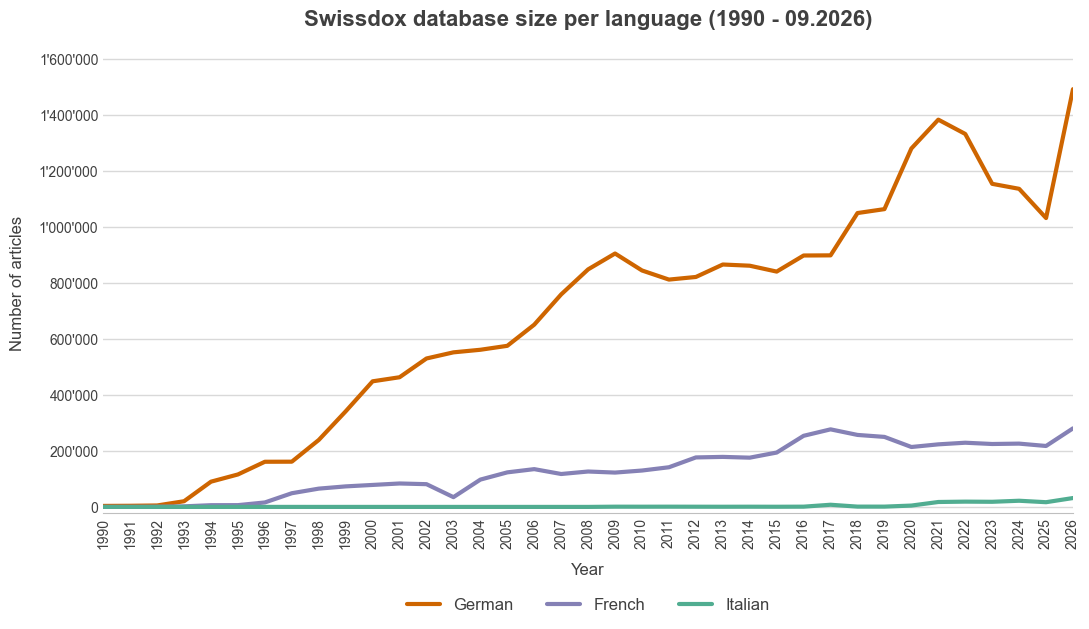

In [18]:
# ============================================================================
# 3.2.1 — PARAMETERS
# ============================================================================
SWISSDOX_SIZE = {
    "Year": list(range(1990, 2027)),
    "German": [3549, 4029, 5130, 20296, 90109, 115899, 161214, 161500, 239029, 341271,
               448464, 462981, 530019, 551901, 561120, 575197, 650793, 758850, 848198,
               904824, 844242, 811704, 821049, 865527, 861258, 840266, 897711, 898229,
               1049305, 1063300, 1279782, 1382820, 1331746, 1153612, 1135833, 1031470, 1491668],
    "French": [33, 223, 559, 2021, 6129, 6323, 15915, 48862, 65272, 73300, 78465, 83660,
               81185, 34863, 97517, 123350, 134898, 117512, 126394, 122600, 129910,
               141582, 176688, 178610, 175831, 194104, 253910, 276931, 257021, 249985,
               213941, 223370, 229202, 224634, 226002, 217568, 280566],
    "Italian": [0, 0, 0, 4, 9, 30, 37, 39, 14, 0, 1, 2, 0, 2, 1, 0, 0, 2, 0, 818, 732,
                848, 700, 582, 727, 562, 880, 7705, 1047, 1014, 4797, 17551, 18815,
                18259, 22006, 16801, 31684],
}

# ============================================================================
# 3.2.1 — PLOT
# ============================================================================
set_style()
swissdox_df = pd.DataFrame(SWISSDOX_SIZE)
name_colors = {LANGUAGE_NAMES[c]: col for c, col in LANGUAGE_COLORS.items()}

plt.figure(figsize=(11, 6.5))
for lang in ["German", "French", "Italian"]:
    plt.plot(swissdox_df["Year"], swissdox_df[lang], label=lang, color=name_colors[lang],
             linewidth=3, solid_capstyle="round")

plt.title("Swissdox database size per language (1990 - 09.2026)", fontsize=16, color=TEXT_COLOR, pad=20)
plt.xlabel("Year", fontsize=12, color=TEXT_COLOR, labelpad=10)
plt.ylabel("Number of articles", fontsize=12, color=TEXT_COLOR, labelpad=10)
plt.xticks(swissdox_df["Year"], rotation=90, fontsize=10, color=TEXT_COLOR)

y_max = max(1_400_000, int(np.ceil(swissdox_df[["German", "French", "Italian"]].values.max() / 200_000) * 200_000))
plt.yticks(list(range(0, y_max + 1, 200_000)), color=TEXT_COLOR)
ax = plt.gca()
ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x)).replace(",", "'")))

plt.grid(True, axis="y", color="#D9D9D9", linewidth=1)
plt.xlim(swissdox_df["Year"].min(), swissdox_df["Year"].max())
plt.ylim(-20000, y_max + 20000)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#BFBFBF")
ax.tick_params(axis="both", which="both", length=0)
plt.legend(loc="lower center", bbox_to_anchor=(0.5, -0.25), ncol=3, frameon=False, fontsize=12)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "3.2.1_swissdox_size.png"), dpi=300, bbox_inches="tight")
plt.show()

## 4.3.1 — Share of articles removed by each filtering step (thesis Figure 8)
Of everything read in (`04_geoparsed`), the share removed as a duplicate, by rubric, as
foreign reporting, by the article-relevance model, and the share that remains.

The relevance decision comes from `06_article_relevance` (`is_relevant_article`). For
articles without such a row (e.g. a folder where that stage was not written), the
fallback in `FIG431_RELEVANCE_FALLBACK` is used and Block output says how many.

DE: 22,999 of 29,757 articles have no 06_article_relevance row — relevance taken from fallback 'impact_sentences'.
FR: 8,667 of 10,626 articles have no 06_article_relevance row — relevance taken from fallback 'impact_sentences'.
IT: 304 of 553 articles have no 06_article_relevance row — relevance taken from fallback 'impact_sentences'.
         Duplicate removal  Rubric removal  Foreign reporting removal  Irrelevance removal  Remaining corpus  total
German                6557            1244                       4718                20093              9664  42276
French                2096            2579                       3551                 8004              2622  18852
Italian                 50             135                        116                  383               170    854


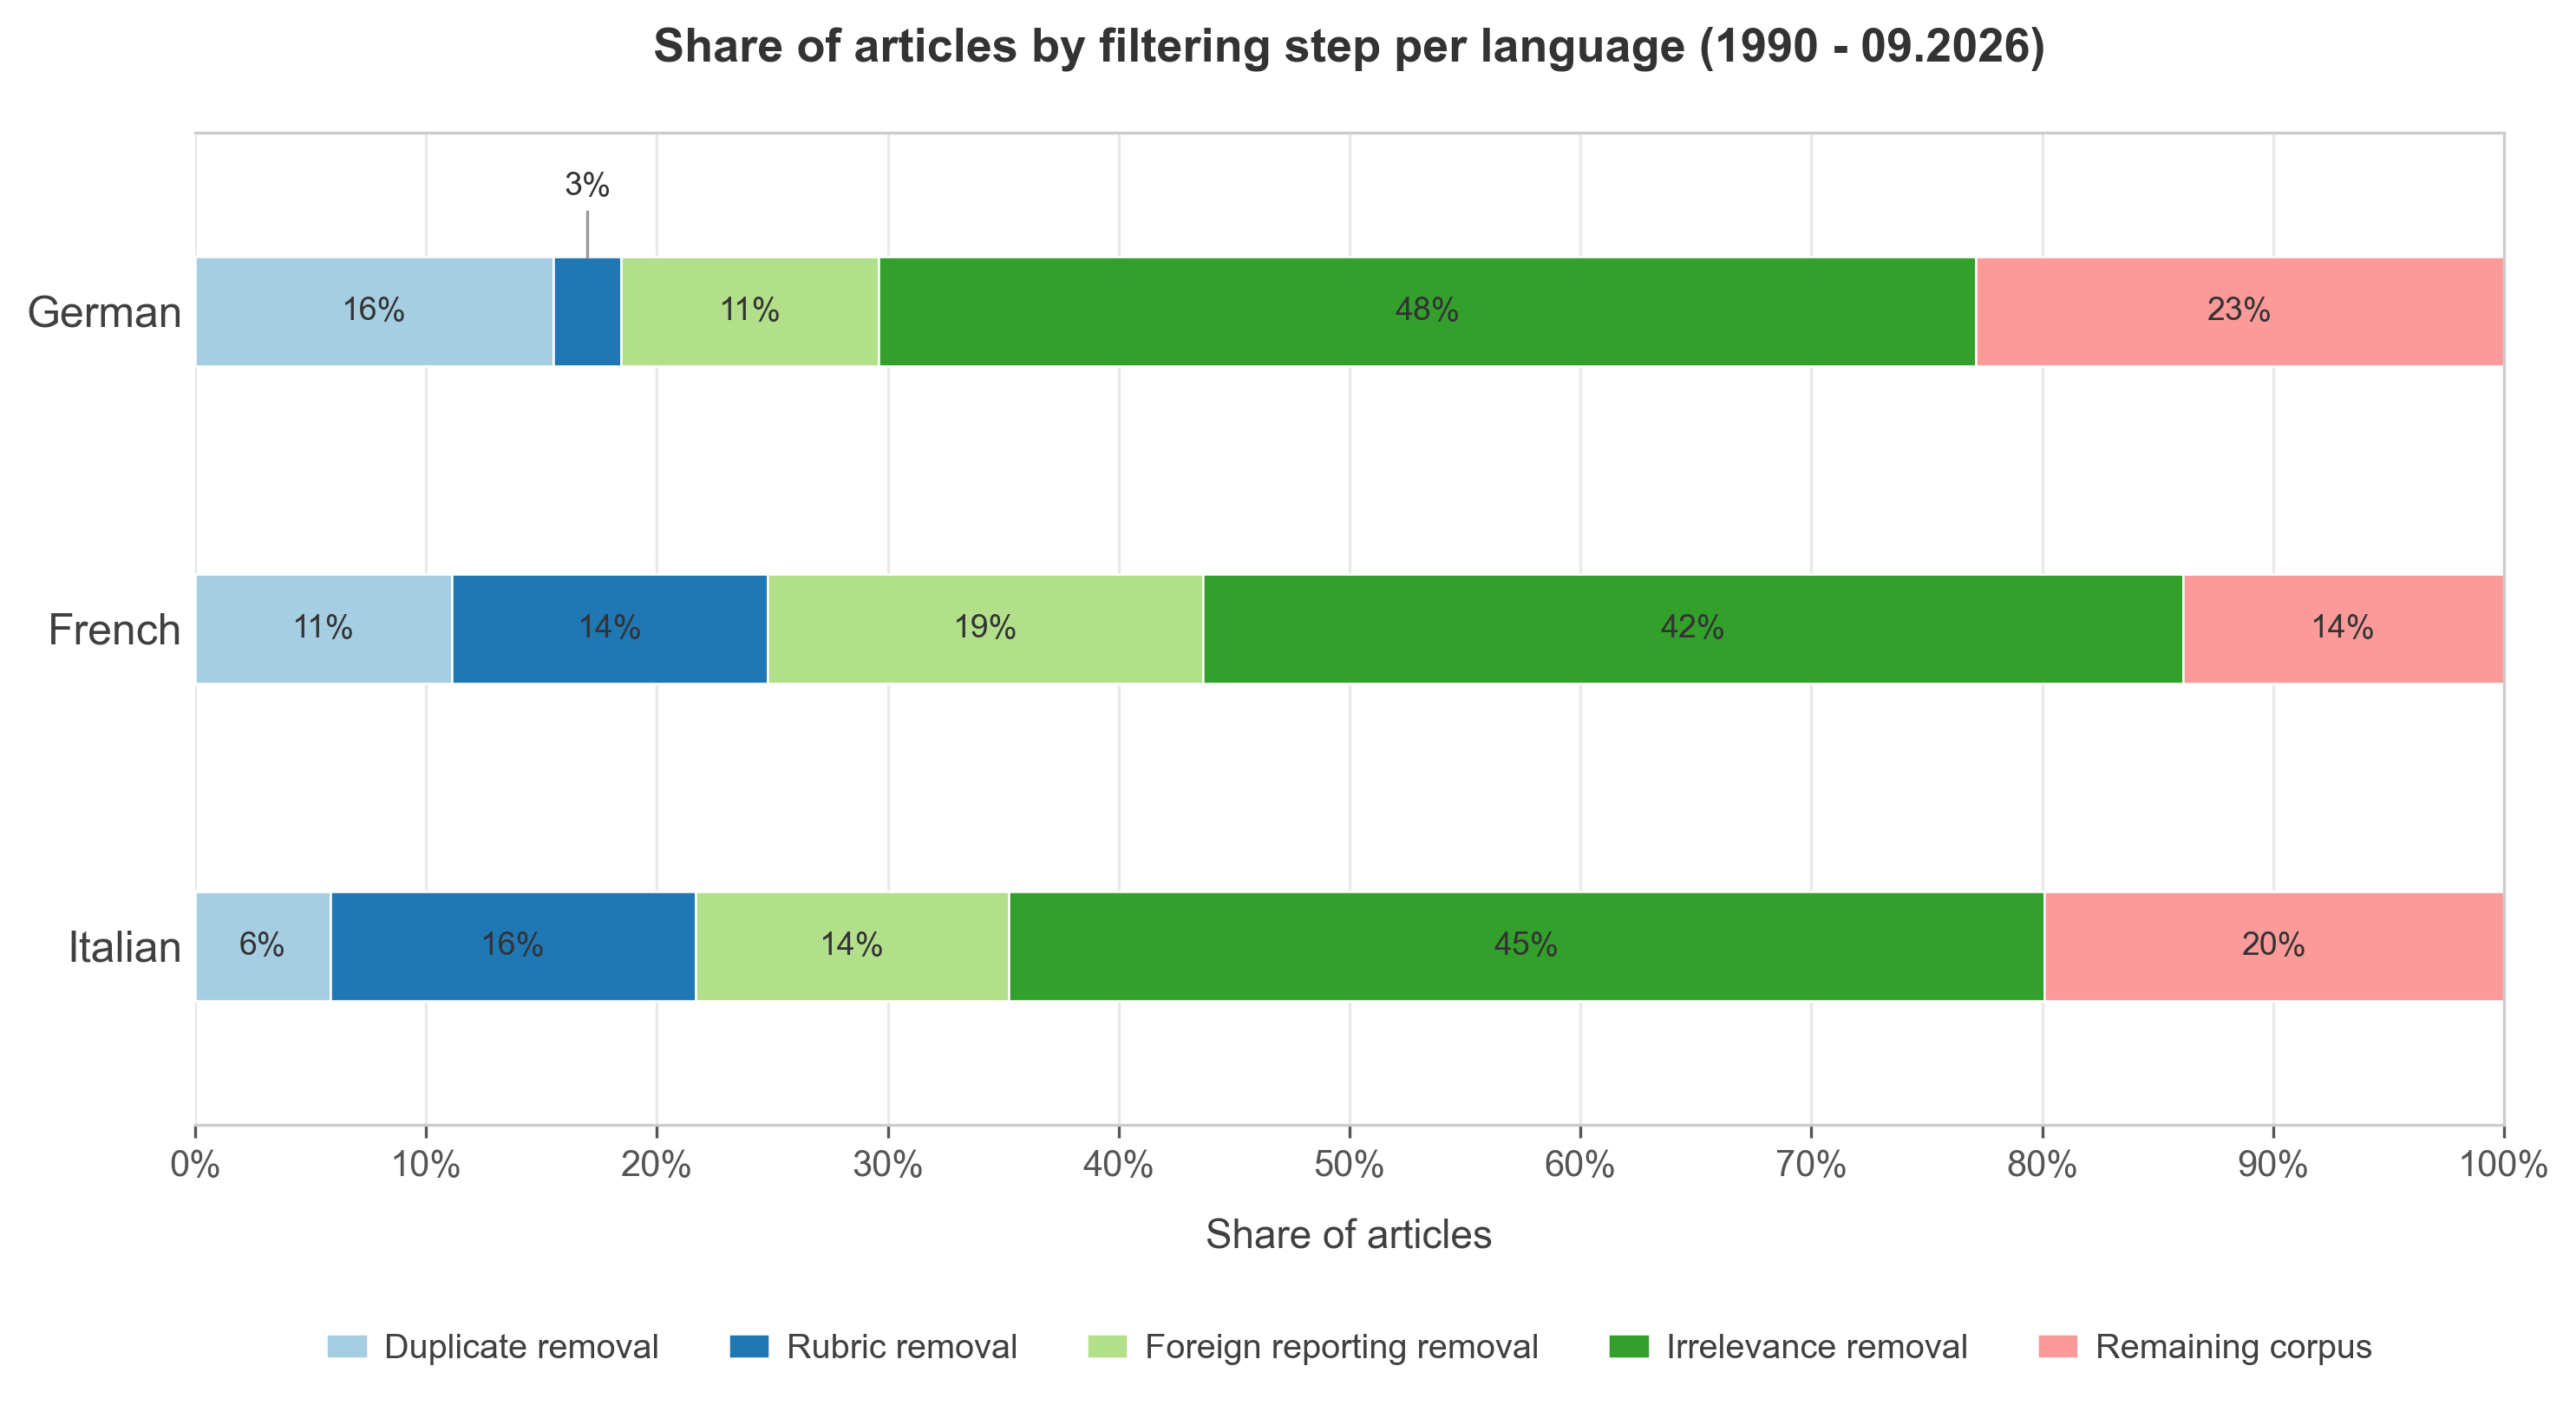

In [19]:
# ============================================================================
# 4.3.1 — PARAMETERS
# ============================================================================
FIG431_LANGUAGES = LANGUAGES

# For articles that passed the rule-based filters but have no 06_article_relevance row:
#   "impact_sentences" -> relevant if the article has impact sentences in 09_impact_predictions
#   "relevant"         -> count them all as relevant
#   "irrelevant"       -> count them all as removed
FIG431_RELEVANCE_FALLBACK = "impact_sentences"

FIG431_LABEL_THRESHOLD = 4.0   # % width below which a label moves above the bar

# ============================================================================
# 4.3.1 — PLOT
# ============================================================================
set_style()
plt.rcParams.update({"text.color": "#404040", "axes.labelcolor": "#404040",
                     "xtick.color": "#404040", "ytick.color": "#404040"})

STEPS = ["Duplicate removal", "Rubric removal", "Foreign reporting removal",
         "Irrelevance removal", "Remaining corpus"]
PAIRED_5 = ["#a6cee3", "#1f78b4", "#b2df8a", "#33a02c", "#fb9a99"]

if filtering_raw.empty:
    print("Skipping: no '04_geoparsed' file found (see Block 2).")
else:
    def _lower(s):
        return s.astype(str).str.strip().str.lower()

    sentence_files = set(zip(sentences["language"], sentences["file"]))
    rows, langs_shown = [], []
    for lang in FIG431_LANGUAGES:
        sub = filtering_raw[filtering_raw["language"] == lang]
        if sub.empty:
            continue
        total = len(sub)
        is_original = _lower(sub["duplicate"]) == "original" if "duplicate" in sub else pd.Series(True, index=sub.index)
        rubric = _lower(sub["rubric_relevance"]) if "rubric_relevance" in sub else pd.Series("relevant", index=sub.index)
        swiss = _lower(sub["swiss"]) if "swiss" in sub else pd.Series("yes", index=sub.index)

        dup_removed = int((~is_original).sum())
        rubric_removed = int((is_original & (rubric == "irrelevant")).sum())
        foreign_removed = int((is_original & (rubric != "irrelevant") & (swiss == "no")).sum())
        if "keep_final" in sub.columns:
            passed = sub[pd.to_numeric(sub["keep_final"], errors="coerce") == 1]
        else:
            passed = sub[is_original & (rubric != "irrelevant") & (swiss != "no")]

        # relevance decision for every article that passed the rule-based filters
        rel = (article_relevance[article_relevance["language"] == lang].set_index("file")["is_relevant_article"]
               if not article_relevance.empty else pd.Series(dtype=object))
        decision = passed["file"].map(rel)
        has_decision = decision.notna()
        relevant = _lower(decision.fillna("")).isin(["yes", "1", "true", "relevant"])
        n_fallback = int((~has_decision).sum())
        if n_fallback:
            if FIG431_RELEVANCE_FALLBACK == "impact_sentences":
                fb = passed["file"].map(lambda f: (lang, f) in sentence_files)
            else:
                fb = pd.Series(FIG431_RELEVANCE_FALLBACK == "relevant", index=passed.index)
            relevant = relevant.where(has_decision, fb)
            print(f"{lang}: {n_fallback:,} of {len(passed):,} articles have no 06_article_relevance row — "
                  f"relevance taken from fallback '{FIG431_RELEVANCE_FALLBACK}'.")
        kept = int(relevant.sum())
        irrelevant_removed = len(passed) - kept

        other = total - dup_removed - rubric_removed - foreign_removed - irrelevant_removed - kept
        if other:
            print(f"  note ({lang}): {other:+,} article(s) don't fit the step logic (keep_final vs. the "
                  f"individual filter columns) — shares are of all {total:,} articles.")
        rows.append([dup_removed, rubric_removed, foreign_removed, irrelevant_removed, kept, total])
        langs_shown.append(lang)

    funnel = pd.DataFrame(rows, index=langs_shown, columns=STEPS + ["total"])
    print(funnel.rename(index=LANGUAGE_NAMES).to_string())
    funnel_pct = funnel[STEPS].div(funnel["total"], axis=0) * 100

    y_pos = np.arange(len(funnel_pct))[::-1] * 1.6   # first language on top
    bar_height = 0.55
    fig_h = 5.5 if len(funnel_pct) >= 3 else 2.2 + 1.1 * len(funnel_pct)
    fig, ax = plt.subplots(figsize=(10, fig_h), dpi=300)

    left = np.zeros(len(funnel_pct))
    last_small_x = {y: -np.inf for y in y_pos}       # stagger neighbouring small labels
    last_small_level = {y: 0 for y in y_pos}
    for step, color in zip(STEPS, PAIRED_5):
        values = funnel_pct[step].values
        ax.barh(y_pos, values, left=left, height=bar_height, label=step,
                color=color, edgecolor="white", linewidth=0.6)
        for y, v, l in zip(y_pos, values, left):
            if v <= 0:
                continue
            x_center = l + v / 2
            if v >= FIG431_LABEL_THRESHOLD:
                ax.text(x_center, y, f"{v:.0f}%", va="center", ha="center", fontsize=9, color="#333333")
            else:
                level = last_small_level[y] + 1 if x_center - last_small_x[y] < 5 else 0
                last_small_x[y], last_small_level[y] = x_center, level
                label_y = y + bar_height / 2 + 0.28 + 0.25 * level
                ax.plot([x_center, x_center], [y + bar_height / 2, label_y - 0.05],
                        color="#999999", linewidth=0.8, zorder=5)
                ax.text(x_center, label_y, f"{v:.0f}%", va="bottom", ha="center",
                        fontsize=9, color="#333333", zorder=5)
        left += values

    ax.set_title("Share of articles by filtering step per language (1990 - 09.2026)", fontsize=13, fontweight="bold",
                 pad=20, color="#333333", loc="center")
    ax.set_xlabel("Share of articles", fontsize=11, labelpad=10)
    ax.set_yticks(y_pos)
    ax.set_yticklabels([LANGUAGE_NAMES.get(l, l) for l in funnel_pct.index], fontsize=12, color="#404040")
    ax.set_ylim(y_pos.min() - 0.9, y_pos.max() + 0.9)
    ax.set_xlim(0, 100)
    ax.set_xticks(np.arange(0, 101, 10))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x)}%"))
    ax.tick_params(axis="x", labelsize=10, colors="#555555")
    ax.grid(axis="x", linestyle="-", color="#E0E0E0", alpha=0.7, zorder=0)
    ax.set_axisbelow(True)
    for spine in ["top", "right", "left", "bottom"]:
        ax.spines[spine].set_color("#CCCCCC")
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    # fixed physical gap below the axis (same as the thesis), whatever the figure height
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0), borderaxespad=5.7, ncol=5, frameon=False,
              fontsize=9.5, handlelength=1.2, handletextpad=0.5)

    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, "4.3.1_filtering_steps.png"), bbox_inches="tight")
    plt.show()

## 4.3.2 — Impact types confused by the multi-label classifier (thesis Figure 9)
For every human-annotated sentence: which label was annotated (`matched_labels`) that
the model did not predict, and which label it predicted instead (`pred_labels`).

The thesis used the model's raw predictions (`*_impact_predictions_no_override.csv`). If
the pipeline overwrites `pred_labels` with the annotation for annotated sentences, the
matrices come out empty — set `FIG432_PRED_COL` to the column that holds the raw
predictions in that case (the cell warns when this seems to be happening).

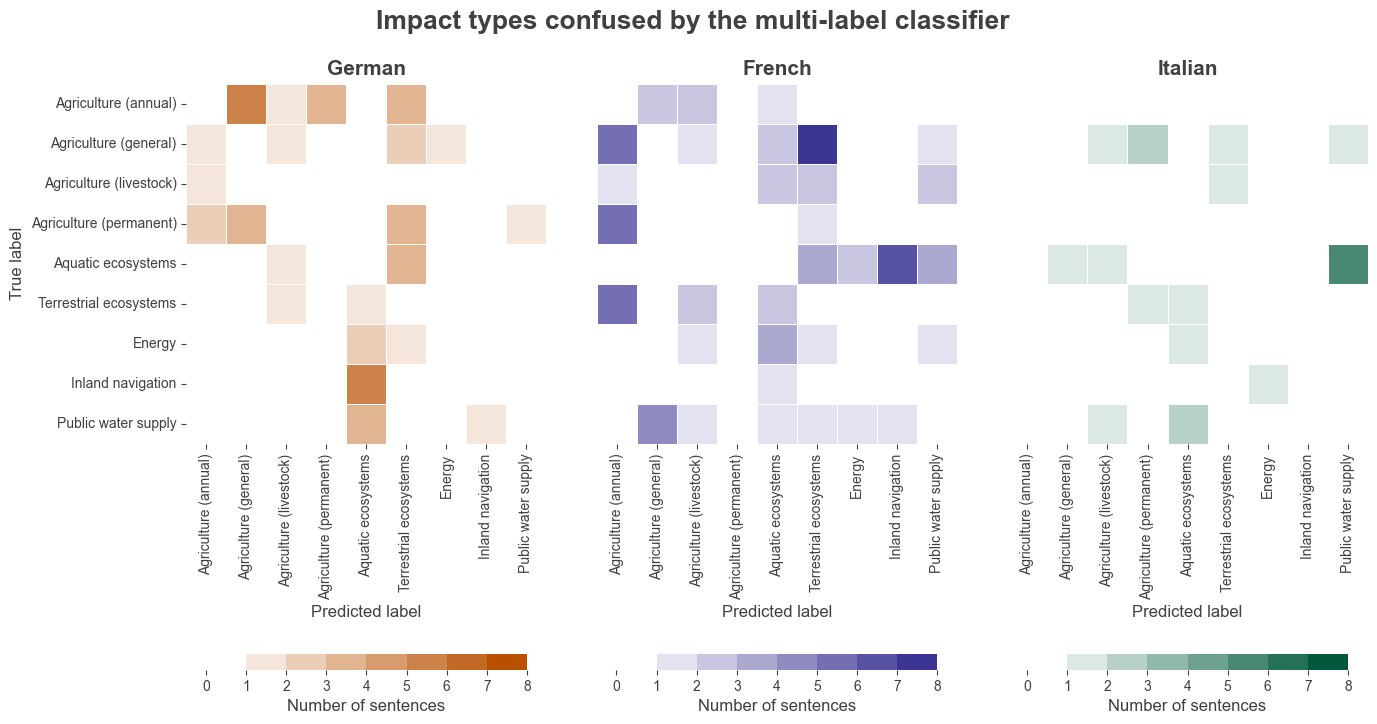

In [20]:
# ============================================================================
# 4.3.2 — PARAMETERS
# ============================================================================
FIG432_LANGUAGES = LANGUAGES
FIG432_PRED_COL = "pred_labels"
FIG432_COLORS = {"DE": "#b85000", "FR": "#3c3594", "IT": "#00593c"}   # darker than the line colours
FIG432_LABEL_DISPLAY_NAMES = {
    "agriculture_annual": "Agriculture (annual)",
    "agriculture_general": "Agriculture (general)",
    "agriculture_livestock": "Agriculture (livestock)",
    "agriculture_permanent": "Agriculture (permanent)",
    "ecosystems_aquatic": "Aquatic ecosystems",
    "ecosystems_terrestrial": "Terrestrial ecosystems",
    "energy": "Energy",
    "inlandnavigation": "Inland navigation",
    "publicwatersupply": "Public water supply",
}

# ============================================================================
# 4.3.2 — PLOT
# ============================================================================
import itertools
import seaborn as sns
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap

set_style()


def strict_confusions(df, pred_col):
    df = df[df["matched_labels_merged"].map(len) > 0]
    labels = sorted(set(itertools.chain.from_iterable(df["matched_labels_merged"])) |
                    set(itertools.chain.from_iterable(df[pred_col])))
    mat = pd.DataFrame(0, index=labels, columns=labels, dtype=int)
    for true_set, pred_set in zip(df["matched_labels_merged"], df[pred_col]):
        true_set, pred_set = set(true_set), set(pred_set)
        for t in true_set:
            if t in pred_set:
                continue
            for p in pred_set:
                if p != t:
                    mat.loc[t, p] += 1
    for l in labels:
        mat.loc[l, l] = 0
    return mat


pred_values = sentences[FIG432_PRED_COL]
if pred_values.map(lambda v: isinstance(v, str)).any():
    pred_values = pred_values.apply(parse_label_list)
sent432 = sentences.assign(**{FIG432_PRED_COL: pred_values})

matrices = {}
for lang in FIG432_LANGUAGES:
    sub = sent432[(sent432["language"] == lang) & (sent432["matched_labels_merged"].map(len) > 0)]
    if sub.empty:
        print(f"{lang}: no annotated sentences — left out.")
        continue
    same = (sub["matched_labels_merged"].map(set) == sub[FIG432_PRED_COL].map(set)).mean()
    if same > 0.99:
        print(f"WARNING ({lang}): predictions equal the annotations on {same:.0%} of annotated sentences — "
              f"'{FIG432_PRED_COL}' may have been overwritten by the annotations (see note above).")
    matrices[lang] = strict_confusions(sub, FIG432_PRED_COL)

if not matrices:
    print("Skipping: no annotated sentences (non-empty matched_labels) found.")
else:
    all_labels = sorted(set().union(*[set(m.index) for m in matrices.values()]))
    formatted = [FIG432_LABEL_DISPLAY_NAMES.get(l, l) for l in all_labels]
    matrices = {l: m.reindex(index=all_labels, columns=all_labels, fill_value=0) for l, m in matrices.items()}
    vmax = max(1, max(int(m.values.max()) for m in matrices.values()))

    fig, axes = plt.subplots(1, len(matrices), figsize=(max(4 * len(matrices) + 2, 7.5), 6.6), constrained_layout=True)
    axes = np.atleast_1d(axes)
    for i, (ax, (lang, mat)) in enumerate(zip(axes, matrices.items())):
        cmap = LinearSegmentedColormap.from_list(f"{lang}_cmap", ["#ffffff", FIG432_COLORS.get(lang, "#444444")])
        cmap.set_under("white")
        norm = BoundaryNorm(np.arange(0, vmax + 1, 1), cmap.N)
        sns.heatmap(mat, ax=ax, cmap=cmap, linewidths=0.5, norm=norm, square=True, cbar=True,
                    cbar_kws={"orientation": "horizontal", "pad": 0.08, "shrink": 0.8,
                              "label": "Number of sentences"})
        ax.set_title(LANGUAGE_NAMES.get(lang, lang), fontsize=15)
        ax.set_xlabel("Predicted label", fontsize=12)
        if i == 0:
            ax.set_ylabel("True label", fontsize=12)
            ax.set_yticklabels(formatted, rotation=0, fontsize=10)
        else:
            ax.set_ylabel("")
            ax.set_yticklabels([])
            ax.tick_params(axis="y", left=False)
        ax.set_xticklabels(formatted, rotation=90, fontsize=10)

    fig.suptitle("Impact types confused by the multi-label classifier", fontsize=19, fontweight="bold", y=1.07)
    plt.savefig(os.path.join(FIGURES_DIR, "4.3.2_confusion_matrices_strict.png"), dpi=300, bbox_inches="tight")
    plt.show()

## 4.4.1 — Drought articles per year, raw and normalised (thesis Figure 10)
Top: number of articles with at least one impact sentence, per year and language.
Bottom: the same as a % of all Swissdox articles in that language and year (needs
`REFERENCE_DATA["swissdox_baseline"]`). Years run continuously, so a year without data
shows as a gap.

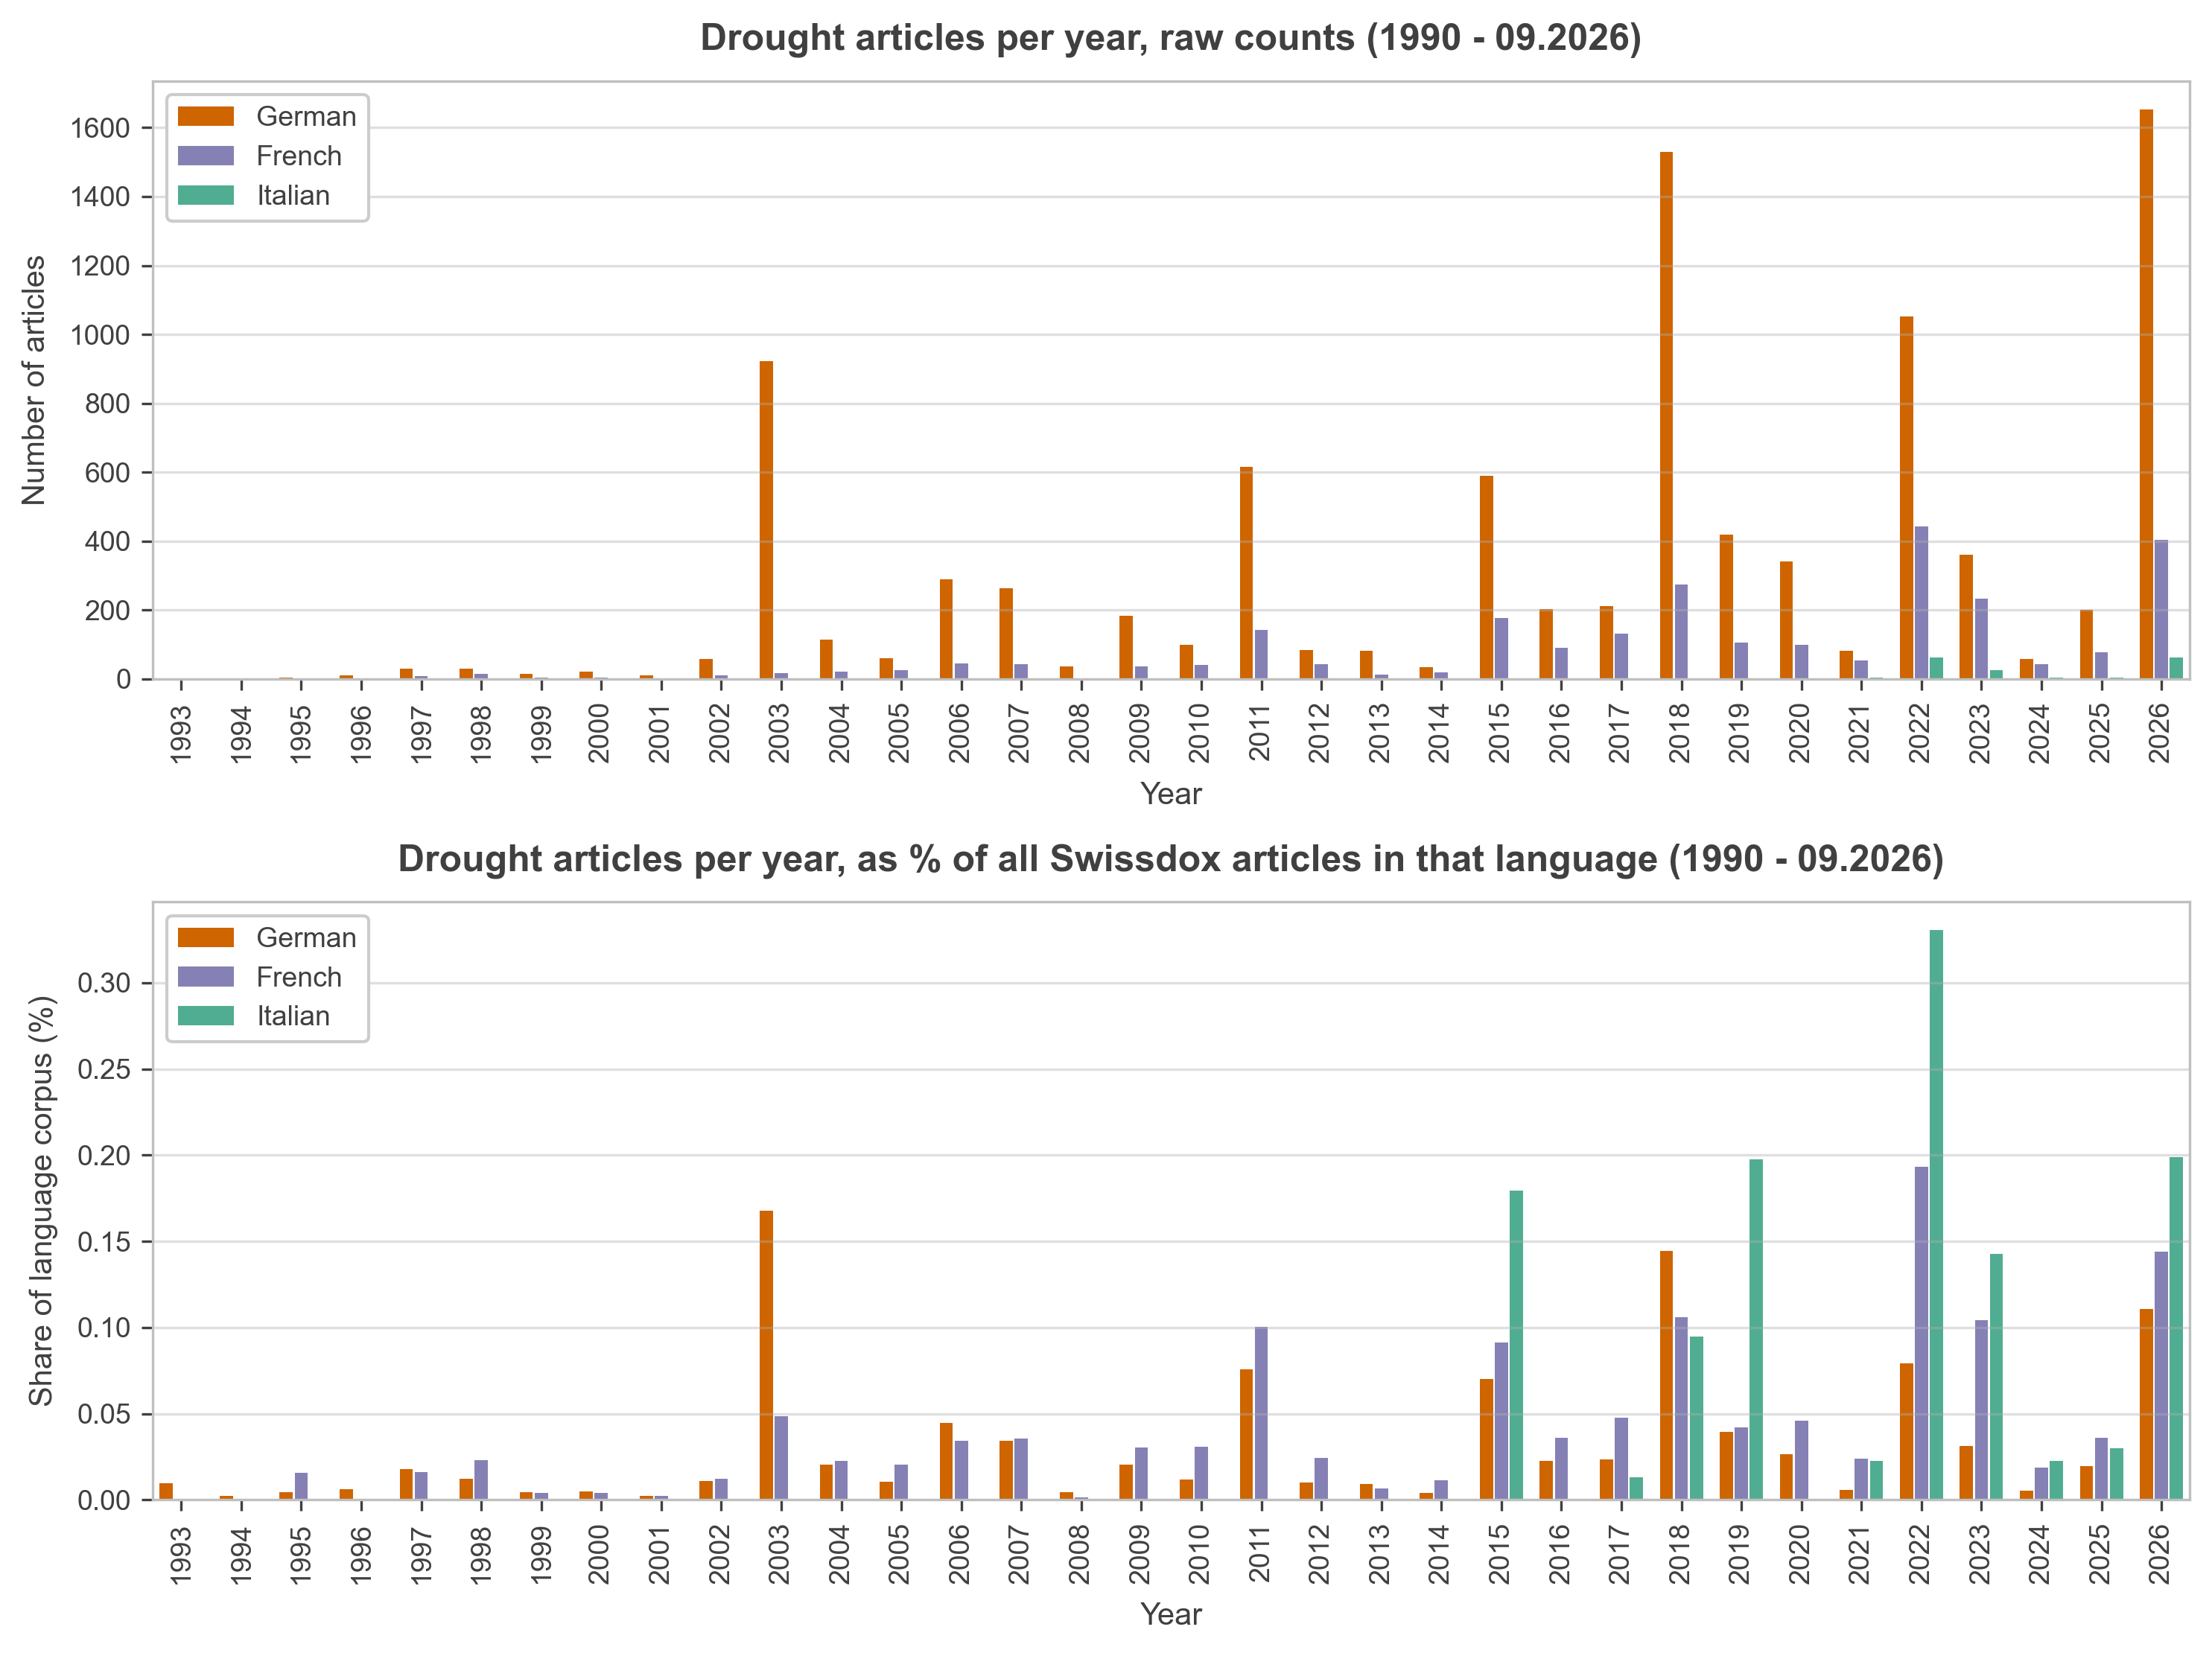

In [21]:
# ============================================================================
# 4.4.1 — PARAMETERS
# ============================================================================
FIG441_LANGUAGES = LANGUAGES
FIG441_START_YEAR = None        # None = first year with data
FIG441_END_YEAR = END_YEAR      # None = last year with data
FIG441_COUNT_UNIT = "articles"  # "articles" (thesis) or "sentences"

# ============================================================================
# 4.4.1 — PLOT
# ============================================================================
set_style()
plt.rcParams.update({"text.color": "#404040", "axes.labelcolor": "#404040",
                     "xtick.color": "#404040", "ytick.color": "#404040"})

sub = sentences[sentences["language"].isin(FIG441_LANGUAGES)].dropna(subset=["year"])
y0, y1 = resolve_year_range(sub["year"], FIG441_START_YEAR, FIG441_END_YEAR)
sub = sub[sub["year"].between(y0, y1)]
if FIG441_COUNT_UNIT == "articles":
    sub = sub.drop_duplicates(["language", "file"])
media_df = (sub.groupby(["year", "language"]).size().unstack("language")
            .reindex(index=range(y0, y1 + 1), columns=FIG441_LANGUAGES).fillna(0))

baseline_path = REFERENCE_DATA.get("swissdox_baseline")
have_baseline = bool(baseline_path) and os.path.exists(baseline_path)
if have_baseline:
    baseline = pd.read_csv(baseline_path)
    baseline["year"] = pd.to_datetime(baseline["week_start"], errors="coerce").dt.year
    baseline_yearly = (baseline.groupby("year")[["de_count", "fr_count", "it_count"]].sum()
                       .rename(columns={"de_count": "DE", "fr_count": "FR", "it_count": "IT"})
                       .reindex(media_df.index))
    norm_df = pd.DataFrame({l: media_df[l] / baseline_yearly[l].replace(0, np.nan) * 100
                            for l in FIG441_LANGUAGES if l in baseline_yearly.columns})
    no_base = [int(y) for y in media_df.index if baseline_yearly.loc[y].isna().all() and media_df.loc[y].sum() > 0]
    if no_base:
        print(f"note: no Swissdox baseline for {no_base} — those years are empty in the bottom panel.")
else:
    print("note: swissdox_baseline not found (see Block 1) — showing raw counts only.")

years = media_df.index
x = np.arange(len(years))
width, gap = 0.22, 0.03
n_l = len(FIG441_LANGUAGES)
total_width = n_l * width + (n_l - 1) * gap
n_panels = 2 if have_baseline else 1

fig, axes = plt.subplots(n_panels, 1, figsize=(10, 3.75 * n_panels), sharex=True, dpi=300)
axes = np.atleast_1d(axes)
panels = [(axes[0], media_df, "Number of articles", "Drought articles per year, raw counts (1990 - 09.2026)")]
if have_baseline:
    panels.append((axes[1], norm_df, "Share of language corpus (%)",
                   "Drought articles per year, as % of all Swissdox articles in that language (1990 - 09.2026)"))

for ax, data, ylabel, title in panels:
    for i, lang in enumerate(FIG441_LANGUAGES):
        if lang in data.columns:
            ax.bar(x + i * (width + gap), data[lang], width=width, label=LANGUAGE_NAMES.get(lang, lang),
                   color=LANGUAGE_COLORS.get(lang))
    ax.set_ylabel(ylabel, fontsize=10, labelpad=6)
    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)
    ax.set_xticks(x + total_width / 2 - width / 2)
    ax.set_xticklabels([int(y) for y in years], fontsize=9, rotation=90)
    ax.tick_params(axis="both", labelsize=9, labelbottom=True)
    ax.set_xlabel("Year", fontsize=10, labelpad=6)
    ax.xaxis.grid(False)
    ax.grid(axis="y", alpha=0.4)
    ax.set_xlim(x[0] - width, x[-1] + total_width)
    leg = ax.legend(fontsize=9, loc="upper left", framealpha=1, facecolor="white")
    leg.set_zorder(10)
    for spine in ax.spines.values():
        spine.set_color("#BFBFBF")
        spine.set_linewidth(0.8)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "4.4.1_yearly_stacked_analysis.png"), bbox_inches="tight")
plt.show()

## 4.4.2 — Average monthly distribution, per language (thesis Figure 11)
Of everything found for a language, the share falling in each calendar month (all years
together). The thesis counted impact sentences (`"sentences"`); `"articles"` counts each
article once.

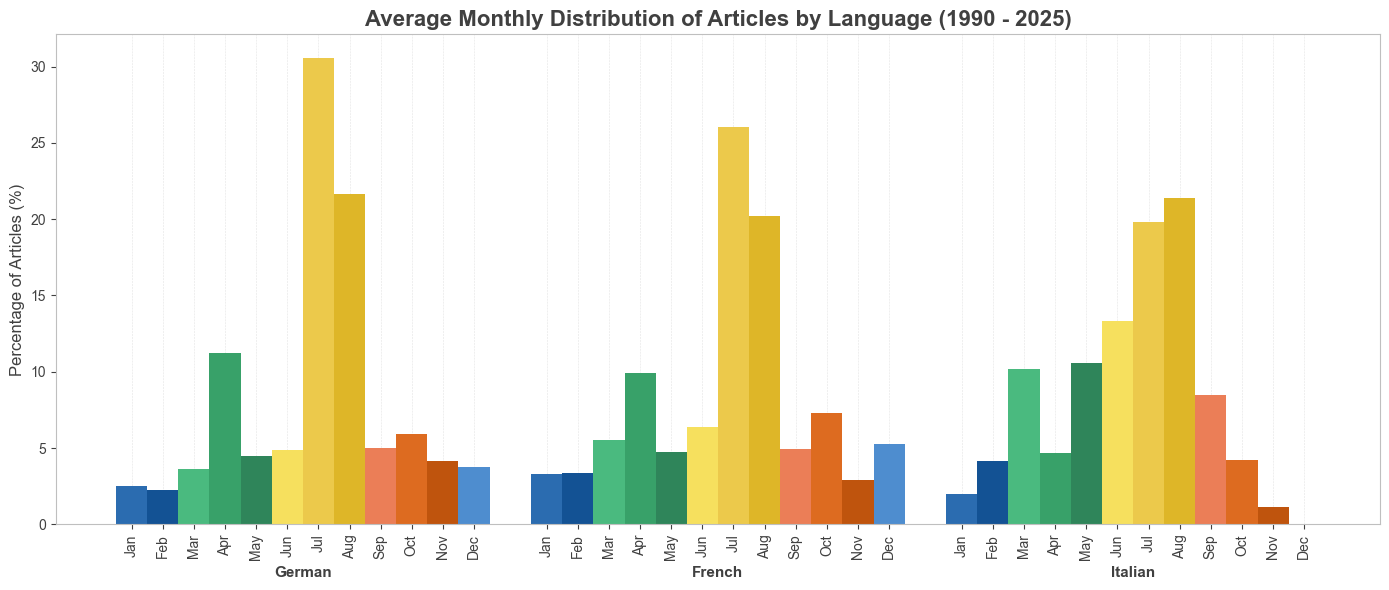

In [22]:
# ============================================================================
# 4.4.2 — PARAMETERS
# ============================================================================
FIG442_LANGUAGES = LANGUAGES
FIG442_START_YEAR = None
FIG442_END_YEAR = 2025
FIG442_COUNT_UNIT = "sentences"   # "sentences" (thesis) or "articles"

# ============================================================================
# 4.4.2 — PLOT
# ============================================================================
set_style()
plt.rcParams.update({"text.color": "#404040", "axes.labelcolor": "#404040",
                     "xtick.color": "#404040", "ytick.color": "#404040"})

MONTH_ORDER = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
MONTH_COLORS = ["#2b6cb0", "#135294", "#4aba7f", "#38a169", "#2f855a", "#f6e05e",
                "#ecc94b", "#deb628", "#eb7e57", "#dd6b20", "#bf540d", "#4e8dcf"]

sub = sentences[sentences["language"].isin(FIG442_LANGUAGES)].dropna(subset=["month"])
y0, y1 = resolve_year_range(sub["year"], FIG442_START_YEAR, FIG442_END_YEAR)
sub = sub[sub["year"].between(y0, y1)]
if FIG442_COUNT_UNIT == "articles":
    sub = sub.drop_duplicates(["language", "file"])

langs442 = [l for l in FIG442_LANGUAGES if (sub["language"] == l).any()]
monthly_df = pd.DataFrame({
    l: (sub.loc[sub["language"] == l, "month"].astype(int).value_counts(normalize=True) * 100)
       .reindex(range(1, 13)).fillna(0).values
    for l in langs442}, index=MONTH_ORDER)

x = np.arange(len(langs442)) * 0.8
width = 0.06
fig, ax = plt.subplots(figsize=(14 if len(langs442) >= 3 else max(6, 4.7 * len(langs442)), 6))

tick_pos, tick_lab = [], []
for i, month in enumerate(MONTH_ORDER):
    positions = x + i * width
    ax.bar(positions, monthly_df.loc[month], width=width, color=MONTH_COLORS[i])
    tick_pos.extend(positions)
    tick_lab.extend([month] * len(langs442))
ax.set_xticks(tick_pos)
ax.set_xticklabels(tick_lab, rotation=90)

group_center = width * (len(MONTH_ORDER) - 1) / 2
for i, lang in enumerate(langs442):
    # placed just below the rotated month labels, independent of the y-axis scale
    ax.annotate(LANGUAGE_NAMES.get(lang, lang), xy=(x[i] + group_center, 0),
                xycoords=("data", "axes fraction"), xytext=(0, -30), textcoords="offset points",
                ha="center", va="top", fontsize=11, fontweight="bold")

ax.set_ylabel("Percentage of Articles (%)" if FIG442_COUNT_UNIT == "sentences" else "Percentage of articles (%)")
ax.set_title("Average Monthly Distribution of Articles by Language (1990 - 2025)")
ax.set_axisbelow(True)
ax.grid(axis="x", linestyle="--", linewidth=0.4, alpha=0.35)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "4.4.2_seasonal_distribution.png"), bbox_inches="tight")
plt.show()

## 4.4.3 — Yearly impact-type composition (thesis Figure 12)
For each year, the share of each broad impact type, stacked to 100%, with the number of
articles as a line. As in the thesis figure, every impact type an article mentions counts
once (`FIG443Y_METHOD = "all_types"`); `"dominant"` keeps only each article's most
frequent type. Only articles whose most salient location lies in a canton are counted.

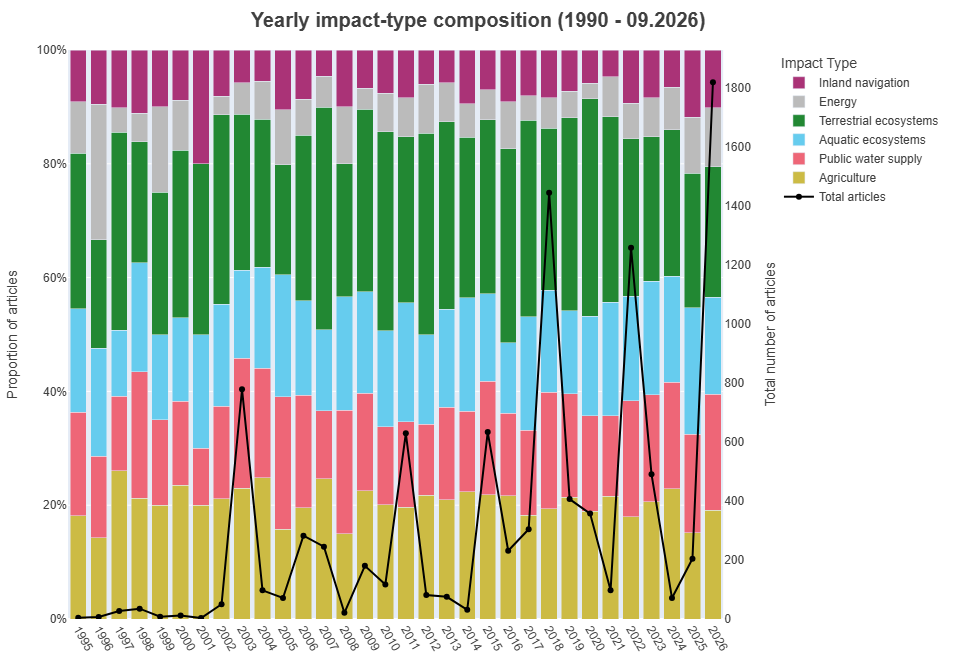

In [23]:
# ============================================================================
# 4.4.3 (yearly) — PARAMETERS
# ============================================================================
FIG443Y_LANGUAGES = LANGUAGES
FIG443Y_START_YEAR = 1995
FIG443Y_END_YEAR = END_YEAR
FIG443_IMPACT_GROUPS = IMPACT_GROUP_ORDER
FIG443_REQUIRE_CANTON = True    # thesis: only articles whose main location is in a canton
# How articles are split across impact types:
#   "all_types" -> every impact type an article mentions counts once (thesis Figure 12)
#   "dominant"  -> only the type(s) with the most impact sentences in the article (thesis Figure 13)
FIG443Y_METHOD = "all_types"

# ============================================================================
# 4.4.3 (yearly) — PLOT
# ============================================================================
import plotly.graph_objects as go
from plotly.subplots import make_subplots


def impact_types_per_article(languages, start_year, end_year, impact_groups, require_canton, method):
    """One row per (article, impact type) that the article is counted under.
    method="dominant": only the type(s) with the most sentences (ties kept);
    method="all_types": every type the article mentions."""
    si = sentence_impacts[sentence_impacts["language"].isin(languages) &
                          sentence_impacts["impact_group"].isin(impact_groups) &
                          sentence_impacts["year"].between(start_year, end_year)]
    if require_canton:
        if best_location.empty:
            print("note: no location data — using all articles instead.")
        else:
            located = best_location.loc[best_location["canton_abbr"].notna(), ["language", "file"]]
            si = si.merge(located, on=["language", "file"], how="inner")
    counts = si.groupby(["language", "file", "year", "month", "impact_group"]).size().reset_index(name="n")
    if method == "all_types":
        return counts
    counts["max_n"] = counts.groupby(["language", "file"])["n"].transform("max")
    return counts[counts["n"] == counts["max_n"]]


def save_plotly(fig, name):
    try:
        fig.write_image(os.path.join(FIGURES_DIR, name), scale=3)
    except Exception as e:
        print(f"note: could not save a PNG copy ({e}). 'pip install -U kaleido' enables saving Plotly figures.")


_years = sentence_impacts.loc[sentence_impacts["language"].isin(FIG443Y_LANGUAGES), "year"]
y0, y1 = resolve_year_range(_years, FIG443Y_START_YEAR, FIG443Y_END_YEAR)
assigned = impact_types_per_article(FIG443Y_LANGUAGES, y0, y1, FIG443_IMPACT_GROUPS, FIG443_REQUIRE_CANTON,
                                    FIG443Y_METHOD)

if assigned.empty:
    print("Skipping: no data for the chosen parameters.")
else:
    yearly = assigned.groupby(["year", "impact_group"]).size().rename("article_count")
    grid = pd.MultiIndex.from_product([sorted(assigned["year"].unique()), FIG443_IMPACT_GROUPS],
                                      names=["year", "impact_group"])
    yearly = yearly.reindex(grid, fill_value=0).reset_index()
    yearly["pair_total"] = yearly.groupby("year")["article_count"].transform("sum")
    yearly = yearly[yearly["pair_total"] > 0].copy()
    yearly["proportion"] = yearly["article_count"] / yearly["pair_total"]

    fig = make_subplots(specs=[[{"secondary_y": True}]])
    for impact in FIG443_IMPACT_GROUPS:
        s = yearly[yearly["impact_group"] == impact]
        fig.add_trace(go.Bar(x=s["year"], y=s["proportion"], name=impact,
                             marker_color=IMPACT_GROUP_COLORS.get(impact, "#999999"),
                             hovertemplate="Year=%{x}<br>Impact=%{fullData.name}<br>Proportion=%{y:.2%}<extra></extra>"),
                      secondary_y=False)
    # line = number of distinct articles per year
    totals = assigned.drop_duplicates(["language", "file"]).groupby("year").size().rename("n").reset_index()
    fig.add_trace(go.Scatter(x=totals["year"], y=totals["n"], name="Total articles",
                             mode="lines+markers", legendrank=1, line=dict(color="black", width=2),
                             marker=dict(size=6), hovertemplate="Year=%{x}<br>Total=%{y}<extra></extra>"),
                  secondary_y=True)
    fig.update_layout(
        barmode="stack", height=650, width=1200,
        title=dict(text="<b>Yearly impact-type composition (1990 - 09.2026)</b>", x=0.5, xanchor="center",
                   y=0.98, yanchor="top", font=dict(family=PLOTLY_FONT["family"], size=20, color=TEXT_COLOR)),
        legend_title_text="Impact Type", margin=dict(t=50, r=50, l=60, b=40), font=PLOTLY_FONT,
    )
    fig.update_yaxes(title_text="Proportion of articles", tickformat=".0%", range=[0, 1], secondary_y=False)
    fig.update_yaxes(title_text="Total number of articles", tickmode="auto", rangemode="tozero",
                     showgrid=False, secondary_y=True)
    fig.update_xaxes(dtick=1, tickangle=60, range=[y0 - 0.5, y1 + 0.5])
    fig.show()
    save_plotly(fig, "4.4.3_yearly_impact_compositions.png")

## 4.4.3 — Monthly impact-type composition (thesis Figure 13)
All years collapsed by calendar month. As in the thesis figure, each article counts under
its dominant impact type (the type with the most impact sentences; ties all kept). The
line is the number of articles per calendar month.

In [24]:
# ============================================================================
# 4.4.3 (monthly) — PARAMETERS
# ============================================================================
FIG443M_LANGUAGES = LANGUAGES
FIG443M_START_YEAR = 1990
FIG443M_END_YEAR = 2025
FIG443M_METHOD = "dominant"     # "dominant" (thesis Figure 13) or "all_types" (see the yearly cell)

# ============================================================================
# 4.4.3 (monthly) — PLOT
# ============================================================================
MONTH_LABELS = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
                7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"}

_years = sentence_impacts.loc[sentence_impacts["language"].isin(FIG443M_LANGUAGES), "year"]
y0, y1 = resolve_year_range(_years, FIG443M_START_YEAR, FIG443M_END_YEAR)
assigned = impact_types_per_article(FIG443M_LANGUAGES, y0, y1, FIG443_IMPACT_GROUPS, FIG443_REQUIRE_CANTON,
                                    FIG443M_METHOD)

if assigned.empty:
    print("Skipping: no data for the chosen parameters.")
else:
    monthly = assigned.groupby(["month", "impact_group"]).size().rename("article_count")
    grid = pd.MultiIndex.from_product([range(1, 13), FIG443_IMPACT_GROUPS], names=["month", "impact_group"])
    monthly = monthly.reindex(grid, fill_value=0).reset_index()
    monthly["pair_total"] = monthly.groupby("month")["article_count"].transform("sum")
    monthly = monthly[monthly["pair_total"] > 0].copy()
    monthly["proportion"] = monthly["article_count"] / monthly["pair_total"]
    monthly["month_name"] = monthly["month"].map(MONTH_LABELS)

    fig = make_subplots(specs=[[{"secondary_y": True}]])
    for impact in FIG443_IMPACT_GROUPS:
        s = monthly[monthly["impact_group"] == impact]
        fig.add_trace(go.Bar(x=s["month_name"], y=s["proportion"], name=impact,
                             marker_color=IMPACT_GROUP_COLORS.get(impact, "#999999"),
                             hovertemplate="Month=%{x}<br>Impact=%{fullData.name}<br>Proportion=%{y:.2%}<extra></extra>"),
                      secondary_y=False)
    # line = number of distinct articles per calendar month
    totals = (assigned.drop_duplicates(["language", "file"]).groupby("month").size()
              .reindex(range(1, 13), fill_value=0).rename("n").reset_index())
    totals["month_name"] = totals["month"].map(MONTH_LABELS)
    fig.add_trace(go.Scatter(x=totals["month_name"], y=totals["n"], name="Total articles",
                             mode="lines+markers", legendrank=1, line=dict(color="black", width=2),
                             marker=dict(size=6), hovertemplate="Month=%{x}<br>Total=%{y}<extra></extra>"),
                  secondary_y=True)
    fig.update_layout(
        barmode="stack", height=650, width=1200,
        title=dict(text="<b>Monthly Proportional Impact-Type Composition (1990 - 2025)</b>", x=0.5, xanchor="center",
                   y=0.98, yanchor="top", font=dict(family=PLOTLY_FONT["family"], size=20, color=TEXT_COLOR)),
        legend_title_text="Impact Type", margin=dict(t=50, r=50, l=60, b=40), font=PLOTLY_FONT,
    )
    fig.update_yaxes(title_text="Proportion of articles", tickformat=".0%", range=[0, 1], secondary_y=False)
    fig.update_yaxes(title_text="Total number of articles", tickmode="auto", rangemode="tozero",
                     showgrid=False, secondary_y=True)
    fig.update_xaxes(tickangle=60, categoryorder="array", categoryarray=list(MONTH_LABELS.values()))
    fig.show()
    save_plotly(fig, "4.4.3_monthly_impact_compositions.png")

## 4.5.1 — Deviation from baseline reporting, chi residuals (thesis Figure 15)
For each canton and year, how much more or less it was reported on than its own
long-term average: `(articles − mean) / √mean`, each article counted in its dominant
canton (as in the thesis). Only years that contain data are drawn, so a year without
any articles doesn't show as a false drop.
Needs `REFERENCE_DATA["canton_tilemap"]`.

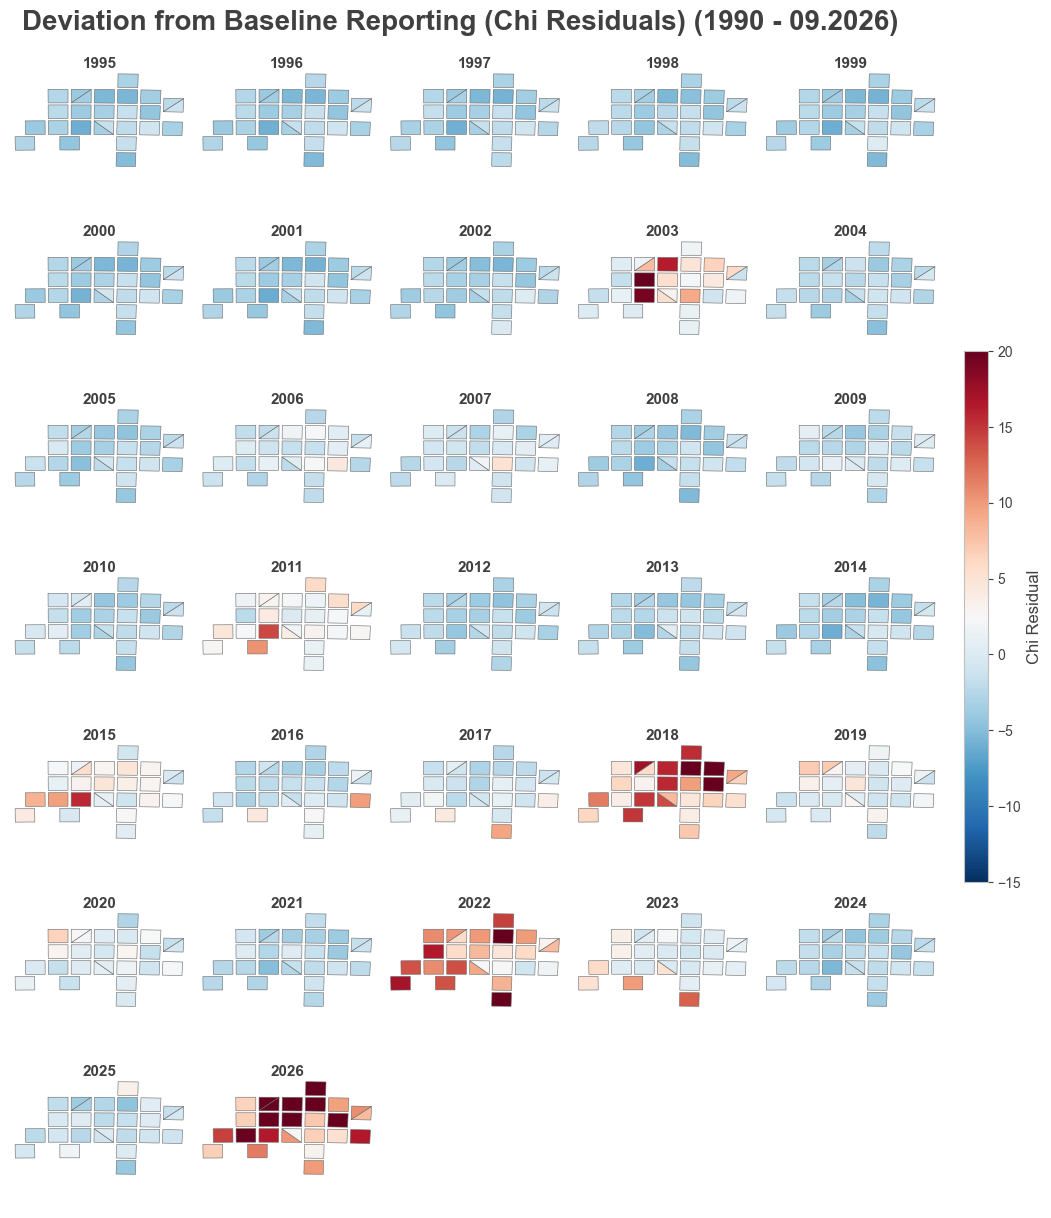

In [25]:
# ============================================================================
# 4.5.1 — PARAMETERS
# ============================================================================
FIG451_LANGUAGES = LANGUAGES
FIG451_START_YEAR = 1995
FIG451_END_YEAR = END_YEAR
FIG451_COUNT = "articles"     # "articles" (thesis: each article's dominant canton) or "clusters" (every salient cluster)
FIG451_N_COLS = 5
FIG451_CHI_VMIN, FIG451_CHI_VMAX = -15, 20
FIG451_CMAP = "RdBu_r"

# ============================================================================
# 4.5.1 — PLOT
# ============================================================================
from matplotlib.colors import Normalize

set_style()
plt.rcParams.update({"text.color": "#404040", "axes.labelcolor": "#404040",
                     "xtick.color": "#404040", "ytick.color": "#404040"})

cantons_gdf = load_canton_tilemap()
source = locations if FIG451_COUNT == "clusters" else article_canton
if cantons_gdf is None or source.empty:
    print("Skipping: needs both the canton tilemap and location data (Block 2).")
else:
    sub = source[source["language"].isin(FIG451_LANGUAGES) & source["canton_abbr"].notna()]
    y0, y1 = resolve_year_range(sub["year"], FIG451_START_YEAR, FIG451_END_YEAR)
    sub = sub[sub["year"].between(y0, y1)]
    years = sorted(sub["year"].dropna().astype(int).unique())
    empty_years = sorted(set(range(y0, y1 + 1)) - set(years))
    if empty_years:
        print(f"note: no located articles in {empty_years} — those years are not drawn.")

    all_cantons = cantons_gdf["canton_abbr"].unique()
    counts = (sub.groupby(["year", "canton_abbr"]).size()
              .reindex(pd.MultiIndex.from_product([years, all_cantons], names=["year", "canton_abbr"]), fill_value=0)
              .rename("article_count").reset_index())
    counts["expected"] = counts.groupby("canton_abbr")["article_count"].transform("mean")
    counts["chi"] = ((counts["article_count"] - counts["expected"]) /
                     np.sqrt(counts["expected"].replace(0, np.nan))).replace([np.inf, -np.inf], np.nan).fillna(0)
    chi_df = counts[["year", "canton_abbr", "chi"]]

    n_rows = int(np.ceil(len(years) / FIG451_N_COLS))
    fig, axes = plt.subplots(n_rows, FIG451_N_COLS, figsize=(12, 13 / 6 * n_rows))
    axes = np.atleast_2d(axes)
    norm = Normalize(vmin=FIG451_CHI_VMIN, vmax=FIG451_CHI_VMAX)
    cmap = plt.get_cmap(FIG451_CMAP)
    xlim, ylim = tilemap_extent(cantons_gdf)

    for idx, year in enumerate(years):
        ax = axes[divmod(idx, FIG451_N_COLS)]
        merged = cantons_gdf.merge(chi_df[chi_df["year"] == year], on="canton_abbr", how="left")
        merged.plot(column="chi", cmap=cmap, norm=norm, ax=ax, edgecolor="#666666", linewidth=0.4,
                    missing_kwds={"color": "#eeeeee"})
        ax.set_title(str(year), fontsize=11, fontweight="bold", pad=2, ha="center")
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
        ax.set_aspect("equal")
        ax.axis("off")
    for idx in range(len(years), n_rows * FIG451_N_COLS):
        axes[divmod(idx, FIG451_N_COLS)].axis("off")

    fig.suptitle("Deviation from Baseline Reporting (Chi Residuals) (1990 - 09.2026)", fontsize=20, fontweight="bold",
                 x=0.5, y=0.9, ha="center")
    fig.subplots_adjust(hspace=0.05, wspace=0.05, right=0.9)
    cbar_h = 0.35
    cbar_ax = fig.add_axes([0.92, (1 - cbar_h) / 2, 0.02, cbar_h])
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    fig.colorbar(sm, cax=cbar_ax).set_label("Chi Residual")

    fig.savefig(os.path.join(FIGURES_DIR, "4.5.1_chi_residual_map.png"), dpi=200, bbox_inches="tight")
    plt.show()

## 4.5.2 — Dominant drought impact per canton per year (thesis Figure 16)
Each article is assigned to its most salient canton. Its impact sentences are turned
into shares summing to 1 (so long articles don't dominate), shares are summed per
canton and year, and the type with the highest share wins. A canton is white when it
has no reporting, fewer than `FIG452_N_MIN` classified articles, or the winner's lead
is below `FIG452_MARGIN_MIN`. Needs `REFERENCE_DATA["canton_tilemap"]`.

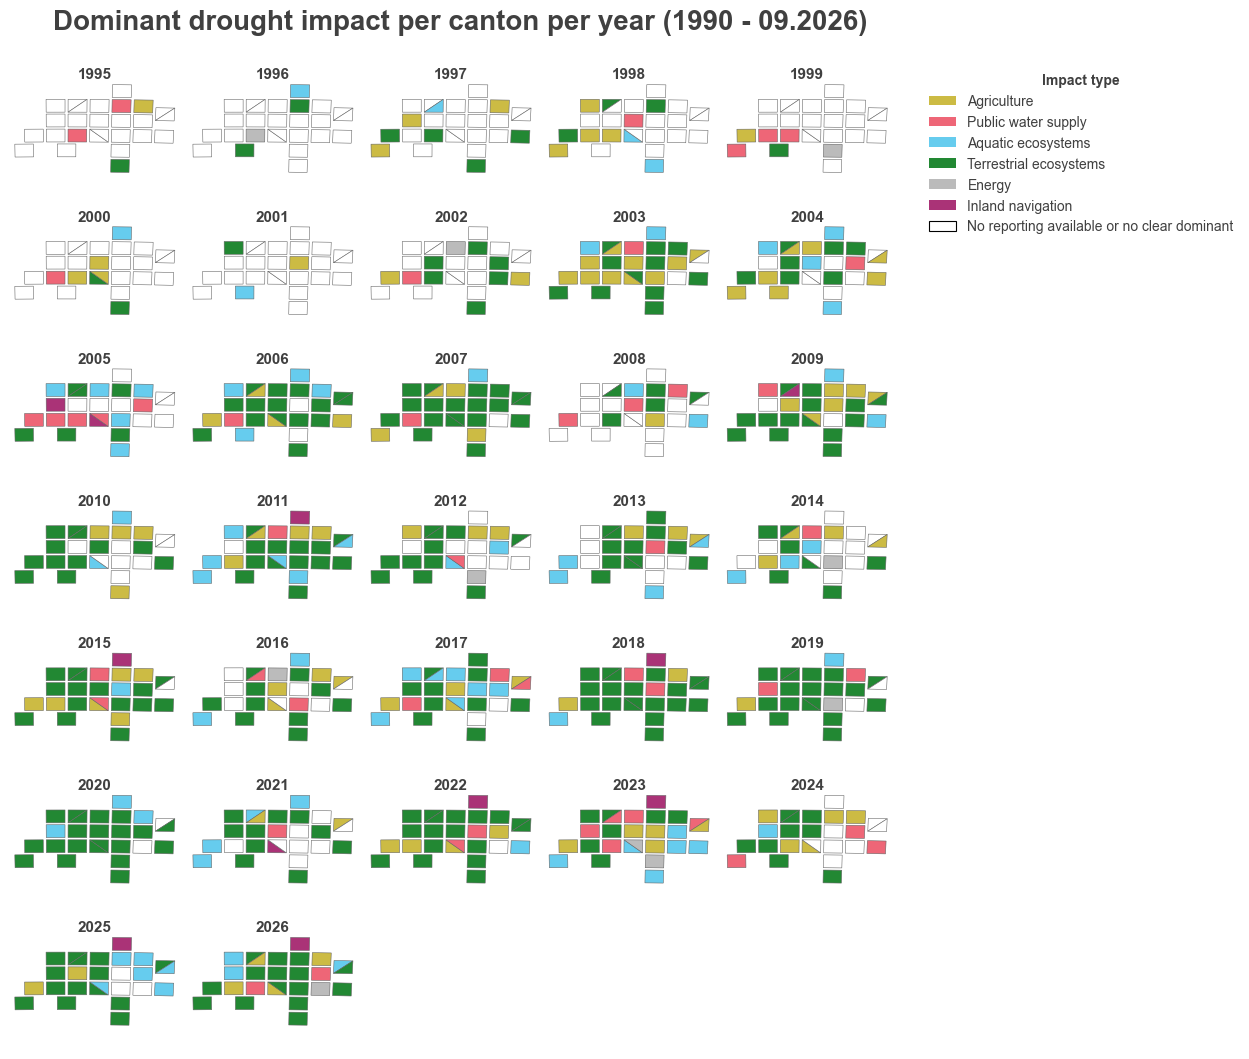

In [26]:
# ============================================================================
# 4.5.2 — PARAMETERS
# ============================================================================
FIG452_LANGUAGES = LANGUAGES
FIG452_START_YEAR = 1995
FIG452_END_YEAR = END_YEAR
FIG452_IMPACT_GROUPS = IMPACT_GROUP_ORDER
FIG452_N_MIN = 1          # minimum classified articles in a canton-year to declare a winner
FIG452_MARGIN_MIN = 0.00  # winner's share must lead the runner-up by at least this
# weight < 1 holds a type to a higher bar (must out-accumulate rivals by 1/weight to win)
FIG452_TYPE_HANDICAP = {"Terrestrial ecosystems": 0.85}
FIG452_N_COLS = 5

# ============================================================================
# 4.5.2 — PLOT
# ============================================================================
from matplotlib.patches import Patch

set_style()
plt.rcParams.update({"text.color": "#404040", "axes.labelcolor": "#404040",
                     "xtick.color": "#404040", "ytick.color": "#404040"})

NO_DOMINANT = "No reporting available or no clear dominant"
cantons_gdf = load_canton_tilemap()
if cantons_gdf is None or article_canton.empty:
    print("Skipping: needs both the canton tilemap and location data (Block 2).")
else:
    ac = article_canton[article_canton["language"].isin(FIG452_LANGUAGES)]
    y0, y1 = resolve_year_range(ac["year"], FIG452_START_YEAR, FIG452_END_YEAR)
    ac = ac[ac["year"].between(y0, y1)][["language", "file", "year", "canton_abbr"]]
    n_spatial = ac.groupby(["year", "canton_abbr"]).size().rename("n_spatial")

    imp = (sentence_impacts[sentence_impacts["impact_group"].isin(FIG452_IMPACT_GROUPS)]
           [["language", "file", "impact_group"]]
           .merge(ac, on=["language", "file"], how="inner"))
    per_art = imp.groupby(["language", "file", "year", "canton_abbr", "impact_group"]).size().rename("n").reset_index()
    per_art["share"] = per_art["n"] / per_art.groupby(["language", "file"])["n"].transform("sum")

    cy = per_art.groupby(["year", "canton_abbr", "impact_group"])["share"].sum().rename("score").reset_index()
    n_art = per_art.groupby(["year", "canton_abbr"])["file"].nunique().rename("n_articles").reset_index()
    cy = cy.merge(n_art, on=["year", "canton_abbr"])
    cy["dominance"] = cy["score"] / cy["n_articles"]
    cy["dom_adj"] = cy["dominance"] * cy["impact_group"].map(FIG452_TYPE_HANDICAP).fillna(1.0)
    cy["rank"] = cy.groupby(["year", "canton_abbr"])["dom_adj"].rank(method="first", ascending=False)
    top = cy[cy["rank"] == 1][["year", "canton_abbr", "impact_group", "dom_adj", "n_articles"]].rename(
        columns={"impact_group": "top_impact", "dom_adj": "adj1"})
    second = cy[cy["rank"] == 2][["year", "canton_abbr", "dom_adj"]].rename(columns={"dom_adj": "adj2"})
    winners = top.merge(second, on=["year", "canton_abbr"], how="left")
    winners["margin"] = winners["adj1"] - winners["adj2"].fillna(0.0)

    years = list(range(y0, y1 + 1))
    grid = (pd.MultiIndex.from_product([years, cantons_gdf["canton_abbr"].unique()], names=["year", "canton_abbr"])
            .to_frame(index=False)
            .merge(n_spatial.reset_index(), on=["year", "canton_abbr"], how="left")
            .merge(winners, on=["year", "canton_abbr"], how="left"))
    grid["n_spatial"] = grid["n_spatial"].fillna(0)
    grid["n_articles"] = grid["n_articles"].fillna(0)
    no_winner = (grid["n_spatial"].eq(0) | grid["top_impact"].isna() |
                 grid["n_articles"].lt(FIG452_N_MIN) | grid["margin"].fillna(0).lt(FIG452_MARGIN_MIN))
    grid["impact_display"] = np.where(no_winner, NO_DOMINANT, grid["top_impact"].astype(object))

    color_map = {**{g: IMPACT_GROUP_COLORS[g] for g in FIG452_IMPACT_GROUPS}, NO_DOMINANT: "#ffffff"}
    grid["color"] = grid["impact_display"].map(color_map)

    n_rows = int(np.ceil(len(years) / FIG452_N_COLS))
    fig, axes = plt.subplots(n_rows, FIG452_N_COLS, figsize=(12, 11 / 6 * n_rows))
    axes = np.atleast_2d(axes)
    xlim, ylim = tilemap_extent(cantons_gdf)

    for idx, year in enumerate(years):
        ax = axes[divmod(idx, FIG452_N_COLS)]
        merged = cantons_gdf.merge(grid.loc[grid["year"] == year, ["canton_abbr", "color"]], on="canton_abbr", how="left")
        merged.plot(color=merged["color"].fillna("#eeeeee").tolist(), ax=ax, edgecolor="#666666", linewidth=0.4)
        ax.set_title(str(year), fontsize=11, fontweight="bold", pad=2, ha="center")
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
        ax.set_aspect("equal")
        ax.axis("off")
    for idx in range(len(years), n_rows * FIG452_N_COLS):
        axes[divmod(idx, FIG452_N_COLS)].axis("off")

    fig.suptitle("Dominant drought impact per canton per year (1990 - 09.2026)", fontsize=20, fontweight="bold",
                 x=0.5, y=0.92, ha="center")
    fig.subplots_adjust(hspace=0.05, wspace=0.05, right=0.86)
    handles = [Patch(facecolor=color_map[l], edgecolor="black" if l == NO_DOMINANT else "none",
                     linewidth=0.8, label=l) for l in color_map]
    legend = fig.legend(handles=handles, title="Impact type", loc="upper left", bbox_to_anchor=(0.88, 0.88),
                        frameon=False, fontsize=10)
    legend.get_title().set_fontweight("bold")

    fig.savefig(os.path.join(FIGURES_DIR, "4.5.2_dominant_impact_map.png"), dpi=200, bbox_inches="tight")
    plt.show()

## 4.6.1 — Top 10 cantons reported on, by language source (thesis Figure 17)
Share of each language's articles whose most salient canton is the given canton. Bars
are coloured by the canton's language region; bilingual cantons (FR/DE) are striped.

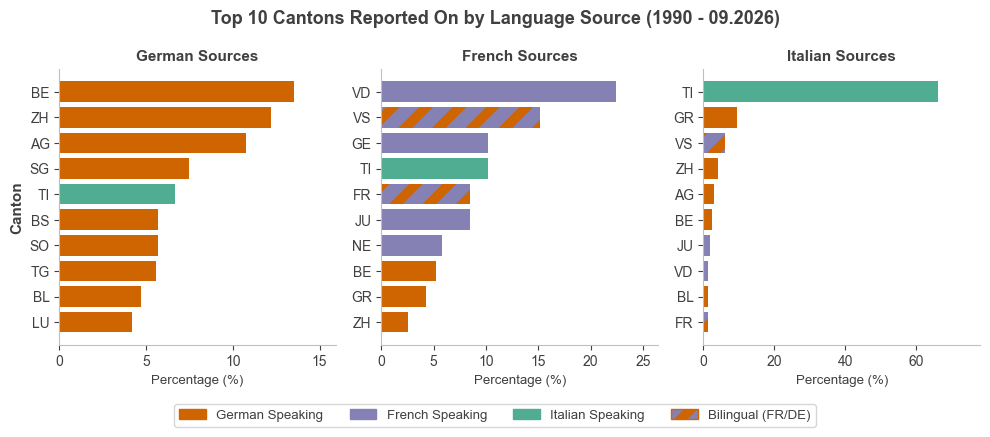

In [27]:
# ============================================================================
# 4.6.1 — PARAMETERS
# ============================================================================
FIG461_LANGUAGES = LANGUAGES
FIG461_START_YEAR = None
FIG461_END_YEAR = END_YEAR
FIG461_TOP_N = 10

# Language region of each canton (bar colour). Cantons listed in FIG461_BILINGUAL are
# drawn striped French/German.
FIG461_CANTON_LANGUAGE = {
    "TI": "IT", "VD": "FR", "GE": "FR", "NE": "FR", "JU": "FR", "VS": "FR", "FR": "FR",
    # everything else: German
}
FIG461_BILINGUAL = ["VS", "FR"]

# ============================================================================
# 4.6.1 — PLOT
# ============================================================================
import matplotlib.patches as mpatches
import seaborn as sns

set_style()
plt.rcParams.update({"text.color": "#404040", "axes.labelcolor": "#404040",
                     "xtick.color": "#404040", "ytick.color": "#404040"})
HATCH = "/"
_old_hatch_lw = plt.rcParams["hatch.linewidth"]
plt.rcParams["hatch.linewidth"] = 7.0      # thick stripes, as in the thesis

if article_canton.empty:
    print("Skipping: no location data (see Block 2).")
else:
    langs461 = [l for l in FIG461_LANGUAGES if (article_canton["language"] == l).any()]
    fig, axes = plt.subplots(1, len(langs461), figsize=(10 / 3 * max(len(langs461), 1.3), 4), sharex=False)
    axes = np.atleast_1d(axes)
    fig.suptitle(f"Top {FIG461_TOP_N} Cantons Reported On by Language Source (1990 - 09.2026)", fontsize=13,
                 fontweight="bold", y=0.98)

    for i, (lang, ax) in enumerate(zip(langs461, axes)):
        sub = article_canton[article_canton["language"] == lang]
        y0, y1 = resolve_year_range(sub["year"], FIG461_START_YEAR, FIG461_END_YEAR)
        sub = sub[sub["year"].between(y0, y1)]
        pct = (sub["canton_abbr"].value_counts(normalize=True) * 100).head(FIG461_TOP_N)
        cantons = list(pct.index)
        colors = [LANGUAGE_COLORS[FIG461_CANTON_LANGUAGE.get(c, "DE")] for c in cantons]
        ypos = np.arange(len(cantons))
        bars = ax.barh(ypos, pct.values, color=colors, height=0.8)
        for bar, c in zip(bars, cantons):
            if c in FIG461_BILINGUAL:
                bar.set_facecolor(LANGUAGE_COLORS["FR"])
                bar.set_hatch(HATCH)
                bar.set_edgecolor(LANGUAGE_COLORS["DE"])
                bar.set_linewidth(0)
        ax.set_yticks(ypos)
        ax.set_yticklabels(cantons)
        ax.invert_yaxis()
        ax.set_title(f"{LANGUAGE_NAMES.get(lang, lang)} Sources", fontsize=11, fontweight="bold", pad=6)
        ax.set_xlabel("Percentage (%)", fontsize=9.5)
        ax.set_ylabel("Canton" if i == 0 else "", fontsize=11, fontweight="bold")
        ax.set_xlim(0, (pct.max() if len(pct) else 1) * 1.18)
        sns.despine(ax=ax)

    handles = [mpatches.Patch(color=LANGUAGE_COLORS["DE"], label="German Speaking"),
               mpatches.Patch(color=LANGUAGE_COLORS["FR"], label="French Speaking"),
               mpatches.Patch(color=LANGUAGE_COLORS["IT"], label="Italian Speaking"),
               mpatches.Patch(facecolor=LANGUAGE_COLORS["FR"], edgecolor=LANGUAGE_COLORS["DE"],
                              hatch=HATCH, label="Bilingual (FR/DE)")]
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, -0.08), ncol=4, fontsize=9.5, frameon=True)
    plt.tight_layout()
    fig.savefig(os.path.join(FIGURES_DIR, "4.6.1_cantons_per_language.png"), dpi=200, bbox_inches="tight")
    plt.show()

plt.rcParams["hatch.linewidth"] = _old_hatch_lw

## 4.6.2 — Impact distribution by language and domestic/outside coverage (thesis Figure 18)
An article is *domestic* when its most salient canton belongs to the language's own
region (`FIG462_HOME_CANTONS`) and *outside* otherwise. Bars show each impact type's
share of that row's article × impact-type pairs; the % in each label is that row's
share of the language's articles.

                         n_articles
German: domestic (92%)         7267
German: outside (8%)            674
French: domestic (71%)         1394
French: outside (29%)           581
Italian: domestic (67%)         100
Italian: outside (33%)           50


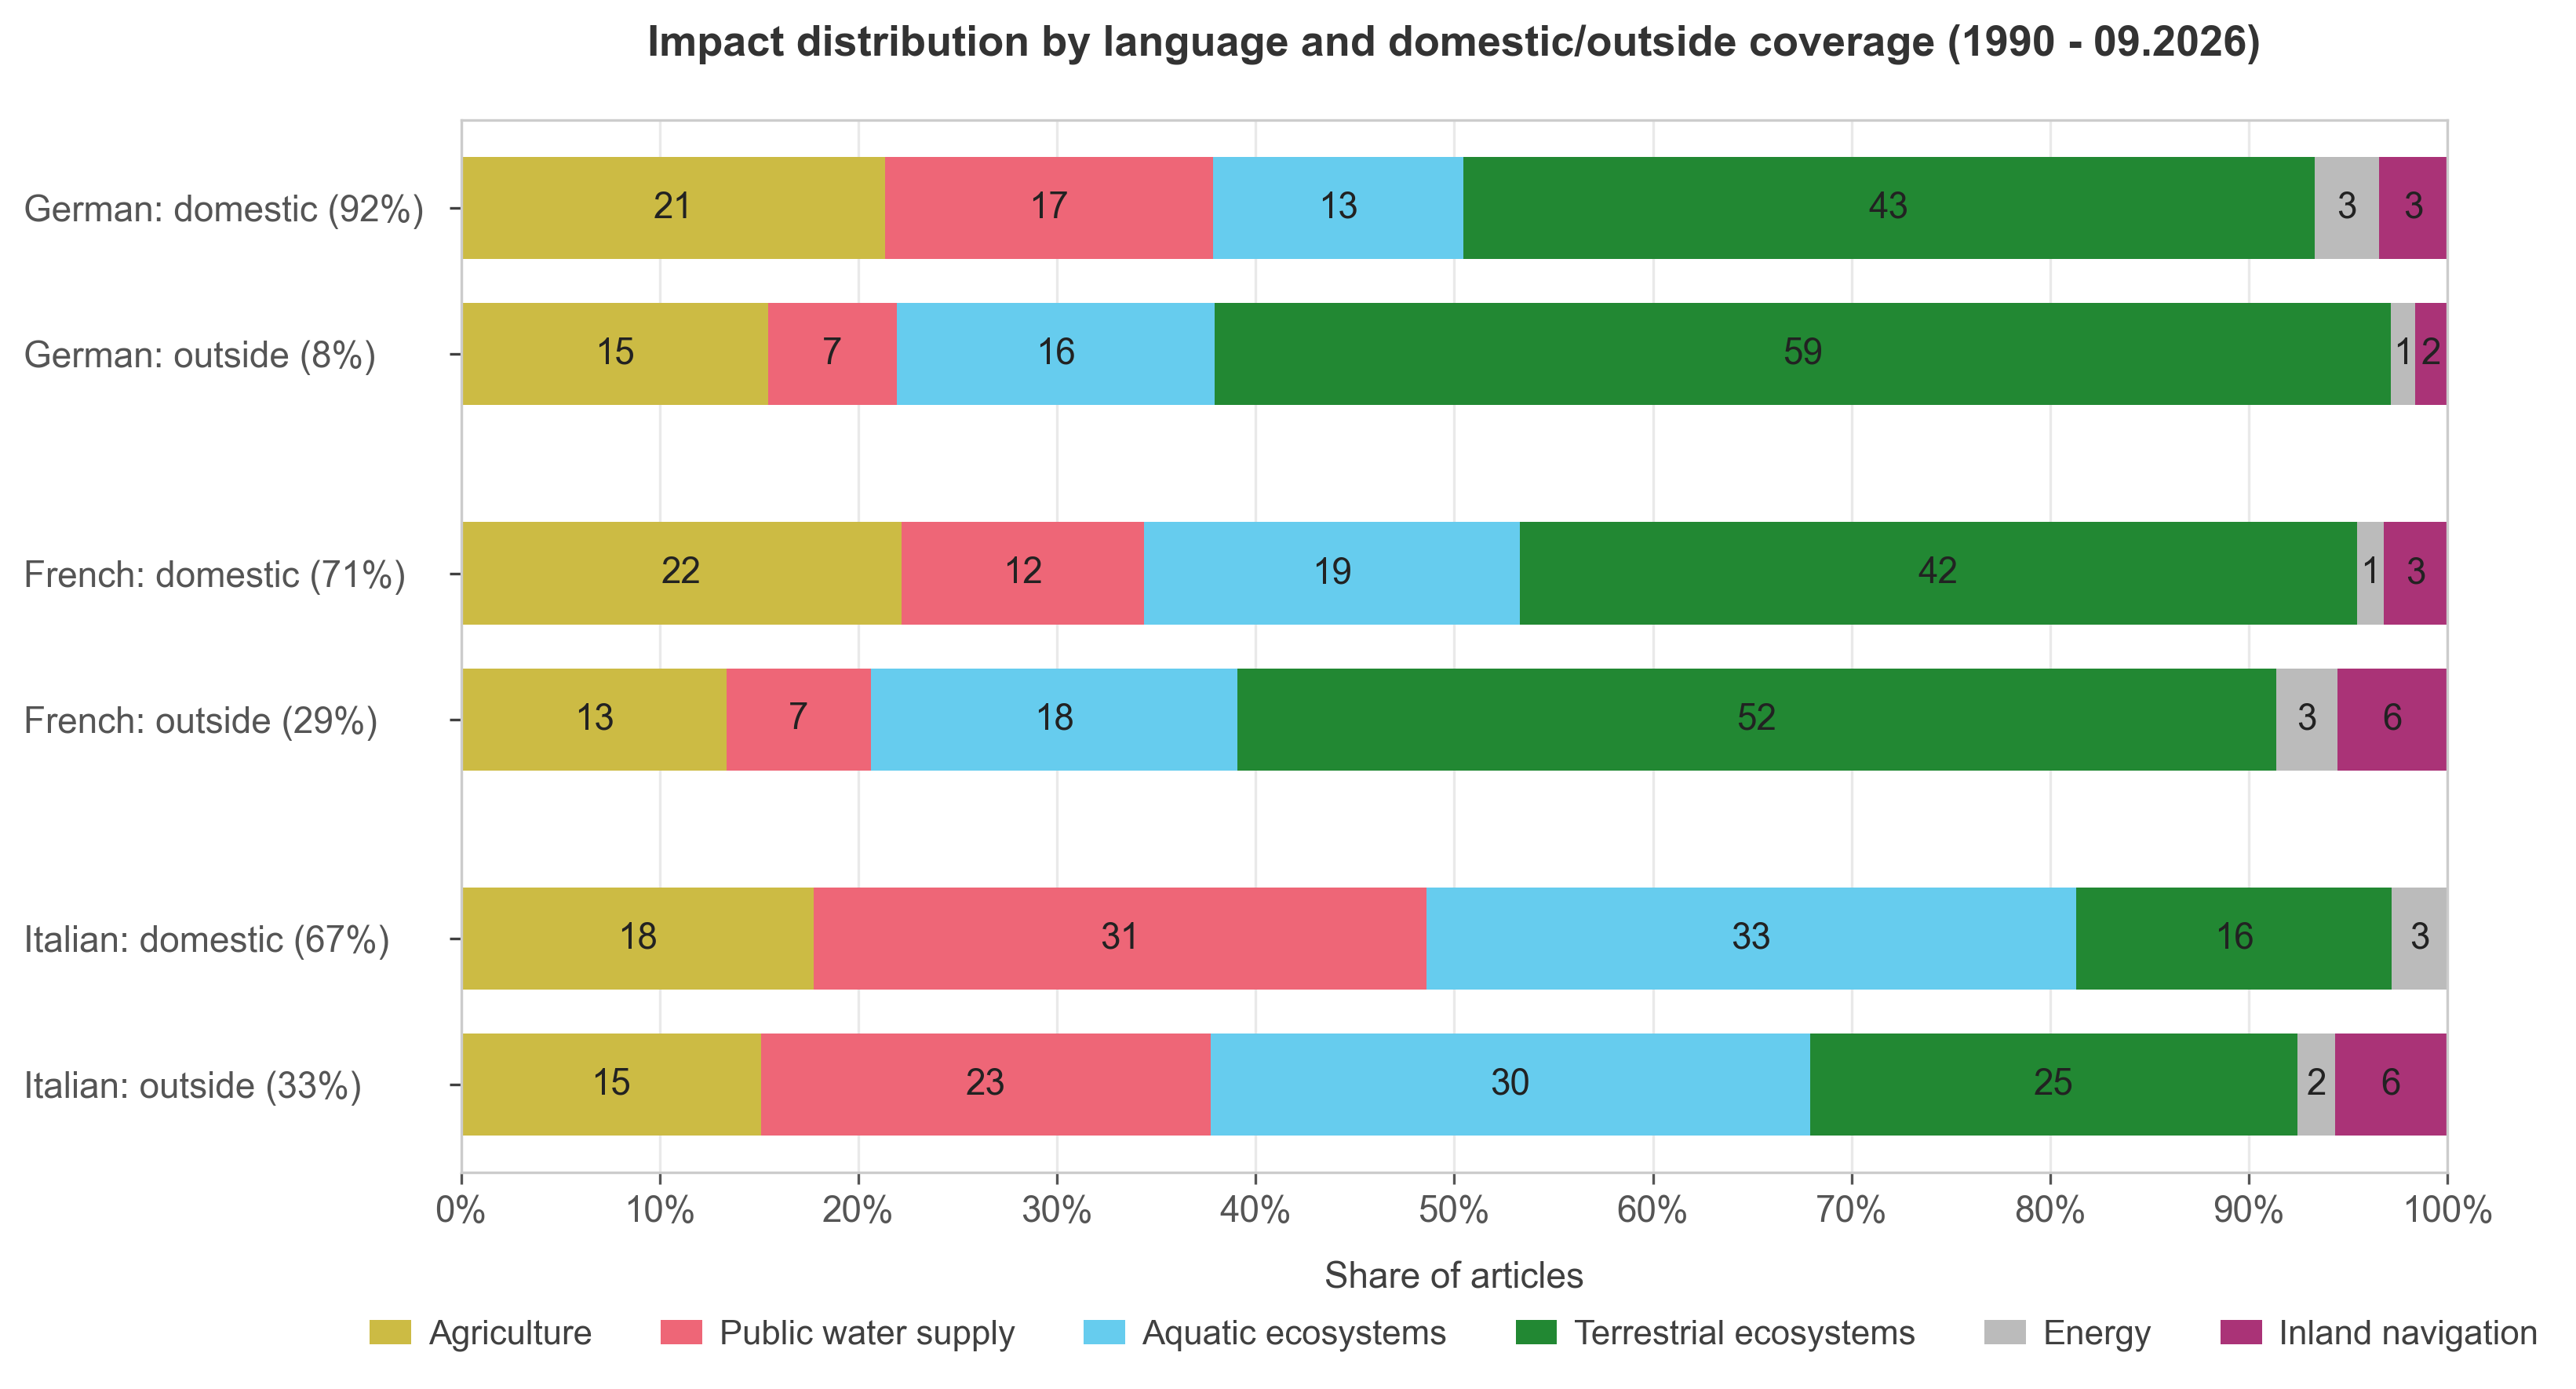

In [28]:
# ============================================================================
# 4.6.2 (bar chart) — PARAMETERS
# ============================================================================
FIG462_LANGUAGES = LANGUAGES
FIG462_START_YEAR = None
FIG462_END_YEAR = END_YEAR
# Bilingual cantons can be listed for more than one language.
# As in the thesis (section 3.9): Valais and Fribourg are domestic for both German and
# French; Bern and Grisons count as German-speaking only.
FIG462_HOME_CANTONS = {
    "DE": ["ZH", "BE", "LU", "UR", "SZ", "OW", "NW", "GL", "ZG", "SO", "BS", "BL",
           "SH", "AR", "AI", "SG", "GR", "AG", "TG", "VS", "FR"],
    "FR": ["GE", "VD", "NE", "JU", "FR", "VS"],
    "IT": ["TI"],
}
FIG462_SECTORS = IMPACT_GROUP_ORDER
# Which impact type(s) an article counts under:
#   "dominant"  -> the type(s) with the most impact sentences in the article (ties kept),
#                  so each article counts (about) once — matches thesis Figure 18
#   "all_types" -> every impact type the article mentions counts once
FIG462_METHOD = "dominant"
FIG462_MIN_ARTICLES = 20   # warn about rows built on fewer articles

# ============================================================================
# 4.6.2 (bar chart) — PLOT
# ============================================================================
set_style()
plt.rcParams.update({"text.color": "#404040", "axes.labelcolor": "#404040",
                     "xtick.color": "#404040", "ytick.color": "#404040"})

if article_canton.empty:
    print("Skipping: needs location data (11_location_clusters) — see Block 2.")
else:
    scope = article_canton[article_canton["language"].isin(FIG462_LANGUAGES)]
    y0, y1 = resolve_year_range(scope["year"], FIG462_START_YEAR, FIG462_END_YEAR)
    scope = scope[scope["year"].between(y0, y1)][["language", "file", "canton_abbr"]].copy()
    home = {l: set(c) for l, c in FIG462_HOME_CANTONS.items()}
    scope["coverage"] = ["domestic" if c in home.get(l, set()) else "outside"
                         for l, c in zip(scope["language"], scope["canton_abbr"])]
    if FIG462_METHOD == "dominant":
        n = (sentence_impacts[sentence_impacts["impact_group"].isin(FIG462_SECTORS)]
             .groupby(["language", "file", "impact_group"]).size().rename("n").reset_index())
        per_article = n[n["n"] == n.groupby(["language", "file"])["n"].transform("max")]
    else:
        per_article = article_impacts[article_impacts["impact_group"].isin(FIG462_SECTORS)]
    impacts = (per_article[["language", "file", "impact_group"]]
               .merge(scope, on=["language", "file"], how="inner"))

    langs462 = [l for l in FIG462_LANGUAGES if (impacts["language"] == l).any()]
    labels, shares, n_rows_art = [], [], []
    for lang in reversed(langs462):               # bottom-to-top: last language first
        sub = impacts[impacts["language"] == lang]
        n_lang = sub["file"].nunique()
        for coverage in ("outside", "domestic"):
            part = sub[sub["coverage"] == coverage]
            counts = part.groupby("impact_group")["file"].nunique().reindex(FIG462_SECTORS, fill_value=0).astype(float)
            shares.append((counts / counts.sum() * 100).fillna(0).values if counts.sum() else counts.values)
            pct_lang = part["file"].nunique() / n_lang * 100 if n_lang else 0
            labels.append(f"{LANGUAGE_NAMES.get(lang, lang)}: {coverage} ({pct_lang:.0f}%)")
            n_rows_art.append(part["file"].nunique())

    if not labels:
        print("Skipping: no articles with both a canton and an impact type.")
    else:
        df462 = pd.DataFrame(shares, index=labels, columns=FIG462_SECTORS)
        print(pd.DataFrame({"n_articles": n_rows_art}, index=labels).iloc[::-1].to_string())
        thin = [l for l, n in zip(labels, n_rows_art) if n < FIG462_MIN_ARTICLES]
        if thin:
            print(f"  WARNING: fewer than {FIG462_MIN_ARTICLES} articles behind {thin} — noisy percentages.")

        y_positions = []
        for i in range(len(langs462)):
            y_positions += [i * 2.5, i * 2.5 + 1]
        fig, ax = plt.subplots(figsize=(11, 6 if len(langs462) >= 3 else 1.2 + 1.6 * len(langs462)), dpi=300)
        left = np.zeros(len(labels))
        for sector in FIG462_SECTORS:
            widths = df462[sector].values
            bars = ax.barh(y_positions, widths, left=left, height=0.7, label=sector,
                           color=IMPACT_GROUP_COLORS[sector], edgecolor="none")
            for bar, w in zip(bars, widths):
                if round(w) > 0:
                    ax.text(bar.get_x() + w / 2, bar.get_y() + bar.get_height() / 2, f"{w:.0f}",
                            va="center", ha="center", color="#222222", fontsize=11)
            left += widths

        ax.set_title("Impact distribution by language and domestic/outside coverage (1990 - 09.2026)",
                     fontsize=13, fontweight="bold", pad=20, color="#333333")
        ax.set_xlabel("Share of articles", fontsize=11, labelpad=10)
        ax.set_yticks(y_positions)
        ax.set_yticklabels(labels, fontsize=11, color="#555555")
        for lab in ax.get_yticklabels():
            lab.set_horizontalalignment("left")
        # left-aligned labels need a gutter as wide as the longest label (130 pt in the thesis)
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        label_pt = max(t.get_window_extent(renderer).width for t in ax.get_yticklabels()) * 72 / fig.dpi
        ax.tick_params(axis="y", pad=max(130, label_pt + 8))
        ax.set_ylim(-0.6, max(y_positions) + 0.6)
        ax.set_xlim(0, 100)
        ax.set_xticks(np.arange(0, 101, 10))
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x)}%"))
        ax.tick_params(axis="x", labelsize=11, colors="#555555")
        ax.grid(axis="x", linestyle="-", color="#E0E0E0", alpha=0.7, zorder=0)
        ax.set_axisbelow(True)
        for spine in ["top", "right", "left", "bottom"]:
            ax.spines[spine].set_color("#CCCCCC")
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0), borderaxespad=3.9, ncol=6,
                  frameon=False, fontsize=10.5, handlelength=1.2, handletextpad=0.5)
        plt.tight_layout()
        plt.savefig(os.path.join(FIGURES_DIR, "4.6.2_domestic_outside.png"), bbox_inches="tight")
        plt.show()

## 4.6.2 — Co-occurrence of impact types, Jaccard similarity (thesis Figure 19)
For each pair of impact types: of all articles mentioning either, the share mentioning
both. As in the thesis, only articles with at least one salient location are used.

Articles used: {'German': 8418, 'French': 2060, 'Italian': 151}


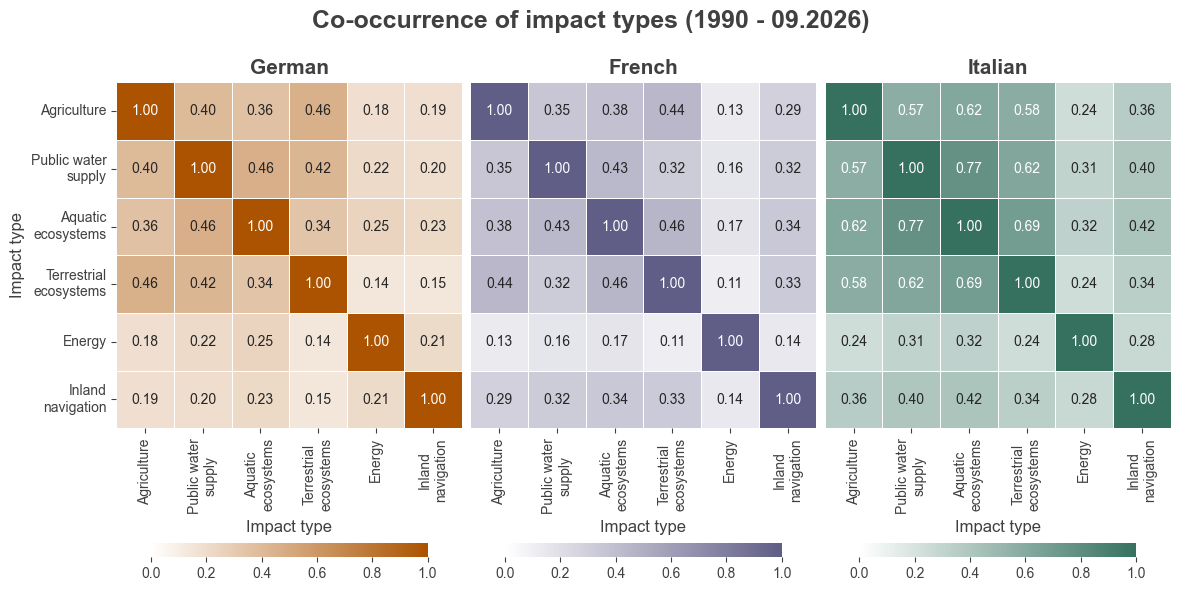

In [29]:
# ============================================================================
# 4.6.2 (heat map) — PARAMETERS
# ============================================================================
FIG462H_LANGUAGES = LANGUAGES
FIG462H_START_YEAR = None
FIG462H_END_YEAR = END_YEAR
FIG462H_IMPACT_GROUPS = IMPACT_GROUP_ORDER
FIG462H_REQUIRE_LOCATION = True
FIG462H_VMIN, FIG462H_VMAX = 0.0, 1.0
FIG462H_COLORS = {"DE": "#AB5300", "FR": "#605D86", "IT": "#36715F"}   # deeper language colours (as in the thesis)
FIG462H_PRETTY = {
    "Public water supply": "Public water\nsupply", "Aquatic ecosystems": "Aquatic\necosystems",
    "Terrestrial ecosystems": "Terrestrial\necosystems", "Inland navigation": "Inland\nnavigation",
}

# ============================================================================
# 4.6.2 (heat map) — PLOT
# ============================================================================
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

set_style()
plt.rcParams.update({"text.color": "#404040", "axes.labelcolor": "#404040",
                     "xtick.color": "#404040", "ytick.color": "#404040"})

ai = article_impacts[article_impacts["language"].isin(FIG462H_LANGUAGES) &
                     article_impacts["impact_group"].isin(FIG462H_IMPACT_GROUPS)]
y0, y1 = resolve_year_range(ai["year"], FIG462H_START_YEAR, FIG462H_END_YEAR)
ai = ai[ai["year"].between(y0, y1)]
if FIG462H_REQUIRE_LOCATION and not locations.empty:
    ai = ai.merge(locations[["language", "file"]].drop_duplicates(), on=["language", "file"], how="inner")


def jaccard_matrix(df, groups):
    binary = (pd.crosstab(df["file"], df["impact_group"]).reindex(columns=groups, fill_value=0) > 0)
    mat = pd.DataFrame(index=groups, columns=groups, dtype=float)
    for a in groups:
        for b in groups:
            union = (binary[a] | binary[b]).sum()
            mat.loc[a, b] = (binary[a] & binary[b]).sum() / union if union else np.nan
    return mat


langs_h = [l for l in FIG462H_LANGUAGES if (ai["language"] == l).any()]
print("Articles used:", {LANGUAGE_NAMES.get(l, l): ai.loc[ai["language"] == l, "file"].nunique() for l in langs_h})
if not langs_h:
    print("Skipping: no data.")
else:
    pretty = [FIG462H_PRETTY.get(g, g) for g in FIG462H_IMPACT_GROUPS]
    fig, axes = plt.subplots(1, len(langs_h), figsize=(11.69 / 3 * len(langs_h) + (0.6 if len(langs_h) < 3 else 0), 5.8),
                             constrained_layout=True)
    axes = np.atleast_1d(axes)
    for i, (ax, lang) in enumerate(zip(axes, langs_h)):
        cmap = LinearSegmentedColormap.from_list(f"{lang}_cmap", ["#ffffff", FIG462H_COLORS.get(lang, "#444444")])
        sns.heatmap(jaccard_matrix(ai[ai["language"] == lang], FIG462H_IMPACT_GROUPS), ax=ax, cmap=cmap,
                    linewidths=0.5, vmin=FIG462H_VMIN, vmax=FIG462H_VMAX, square=True, cbar=True,
                    annot=True, fmt=".2f", cbar_kws={"orientation": "horizontal", "pad": 0.02, "shrink": 0.8})
        ax.set_title(LANGUAGE_NAMES.get(lang, lang), fontsize=15, fontweight="bold")
        ax.set_xlabel("Impact type", fontsize=12)
        if i == 0:
            ax.set_ylabel("Impact type", fontsize=12)
            ax.set_yticklabels(pretty, rotation=0, fontsize=10)
        else:
            ax.set_ylabel("")
            ax.set_yticklabels([])
            ax.tick_params(axis="y", left=False)
        ax.set_xticklabels(pretty, rotation=90, fontsize=10)

    fig.suptitle("Co-occurrence of impact types (1990 - 09.2026)", fontsize=18, fontweight="bold", ha="center")
    fig.get_layout_engine().set(h_pad=0.05, hspace=0.02)
    fig.savefig(os.path.join(FIGURES_DIR, "4.6.2_impact_jaccard_heatmaps.png"), dpi=300, bbox_inches="tight")
    plt.show()

## 4.7 — Media coverage vs. regional drought indicators (processing)
**Run this cell before the 4.7.x figures.** Every place mention (`10_locations_raw`,
minus generic toponyms) is assigned to a BAFU region; monthly media coverage per region
(normalised by the Swissdox baseline) is correlated with each of the 18 indicators.
Needs `REFERENCE_DATA["bafu_regions"]`, `["meteo_indicators"]` and `["swissdox_baseline"]`.

In [30]:
# ============================================================================
# 4.7 — PARAMETERS
# ============================================================================
FIG47_LANGUAGES = LANGUAGES
FIG47_START_YEAR = 2000
FIG47_END_YEAR = END_YEAR          # None = last year of the meteo data
FIG47_WINSORIZE_TOP = 0.02         # pooled-language scan: cap the top 2% of normalised media
FIG47_MIN_OBS = 24                 # months of overlap needed per region/indicator
FIG47_LANG_START_YEAR = {"DE": 1990, "FR": 1990, "IT": 2015}

# Toponyms too generic to locate (removed), plus any name containing the whole word
# canton / cantone / kanton.
FIG47_TOPONYM_COLUMN = "matched_name"
FIG47_TOPONYM_BLACKLIST = {
    "Rhein", "Bezirk Mittelland", "FHNW Fachhochschule Nordwestschweiz, Muttenz",
    "Müllverbrennungsanlage Linthgebiet", "Luzerner Kantonsspital Luzern", "Mittelpunkt der Schweiz",
    "Wahlkreis Rheintal", "Trimbach, Baselbieter", "Alp", "Tóss", "Europa", "Erde", "Franken",
    "Solothurner Spitäler AG, Spital Grenchen", "Alpes", "Canton", "Europe", "Cantone", "Switzerland",
}

FIG47_DROUGHT_VARS = [
    "cdi", "precip_1m_index", "precip_3m_index", "precip_24m_index", "hydro_index",
    "soil_moisture_index", "precip_sum_1m", "precip_sum_3m", "precip_sum_6m",
    "precip_sum_12m", "precip_sum_24m", "spi_1m", "spi_3m", "spi_6m", "spi_12m",
    "spi_24m", "soil_moisture_ufc", "vhi",
]
DROUGHT_VAR_LABELS = {
    "cdi": "CDI", "precip_1m_index": "Precip. 1m index", "precip_3m_index": "Precip. 3m index",
    "precip_24m_index": "Precip. 24m index", "hydro_index": "Hydro index",
    "soil_moisture_index": "Soil moisture index", "precip_sum_1m": "Precip. sum 1m",
    "precip_sum_3m": "Precip. sum 3m", "precip_sum_6m": "Precip. sum 6m",
    "precip_sum_12m": "Precip. sum 12m", "precip_sum_24m": "Precip. sum 24m",
    "spi_1m": "SPI-1", "spi_3m": "SPI-3", "spi_6m": "SPI-6", "spi_12m": "SPI-12",
    "spi_24m": "SPI-24", "soil_moisture_ufc": "Soil moisture UFC", "vhi": "VHI",
}
REGION_MAP = {
    "östlicher Jura": 31, "Balsthal": 32, "Unteres Emmental": 33, "Berner Mittelland": 34,
    "Westliches Berner Oberland": 35, "Greyerzerland": 36, "Oberaargau": 37,
    "Oberes Emmental": 38, "Freiamt": 39, "westliche Zentralschweiz": 40,
    "Östliches Berner Oberland": 41, "östliches Mittelland": 42, "Zürichseebecken": 43,
    "östliche Zentralschweiz": 44, "Urner Alpen": 45, "Surselva": 46, "Alpstein": 47,
    "Glarner Alpen": 48, "nördliches Mittelbünden": 49, "südliches Mittelbünden": 50,
    "Rheintal": 51, "Prättigau": 52, "Freiberge": 53, "westlicher Jura": 54,
    "westliches Mittelland": 55, "Genferseebecken": 56, "Chablais": 57,
    "Walliser Südalpen": 58, "nördliches Wallis": 59, "Vispertäler": 60,
    "Aletschgebiet": 61, "Westliches Tessin": 62, "Nordtessin": 63, "Östliches Tessin": 64,
    "Sottoceneri": 65, "Bündner Südtäler": 66, "Oberengadin": 67, "Unterengadin": 68,
}
ID_TO_REGION = {v: k for k, v in REGION_MAP.items()}

# ============================================================================
# 4.7 — PROCESSING
# ============================================================================
import re
from scipy.stats import pearsonr, spearmanr
from scipy.stats.mstats import winsorize

FIG47_READY = True
meteo_path = REFERENCE_DATA.get("meteo_indicators")
baseline_path = REFERENCE_DATA.get("swissdox_baseline")
if raw_mentions.empty:
    print("Skipping 4.7: no raw place mentions (10_locations_raw) — see Block 2.")
    FIG47_READY = False
regions_gdf = load_bafu_regions(REGION_MAP) if FIG47_READY else None
if FIG47_READY and regions_gdf is None:
    FIG47_READY = False
if FIG47_READY and not (meteo_path and os.path.exists(meteo_path)):
    print(f"Skipping 4.7: meteo indicators not found at '{meteo_path}'.")
    FIG47_READY = False
if FIG47_READY and not (baseline_path and os.path.exists(baseline_path)):
    print(f"Skipping 4.7: swissdox baseline not found at '{baseline_path}'.")
    FIG47_READY = False

if FIG47_READY:
    import geopandas as gpd

    def safe_divide(num, den):
        return np.where(den.notna() & (den != 0), num / den, np.nan)

    def adjust_drought_direction(series, var):
        """Higher value = more drought, for every indicator."""
        if var in ("cdi", "precip_1m_index", "precip_3m_index", "precip_24m_index", "hydro_index",
                   "soil_moisture_index"):
            return series - 1
        if "spi" in var or "precip_sum" in var or "soil_moisture_ufc" in var or "vhi" in var:
            return -series
        return series

    def winsorize_series(series, top=0.0):
        if series.dropna().empty:
            return series
        return pd.Series(winsorize(series, limits=[0, top]), index=series.index)

    # --- monthly drought indicators per region ---
    drought_raw = pd.read_csv(meteo_path, skiprows=3, sep=";")
    drought_raw["measured_at"] = pd.to_datetime(drought_raw["measured_at"], format="%d.%m.%Y")
    drought_raw["year"] = drought_raw["measured_at"].dt.year
    drought_raw["month"] = drought_raw["measured_at"].dt.month
    drought_raw["month_start"] = drought_raw["measured_at"].dt.to_period("M").dt.to_timestamp()
    drought_monthly = drought_raw.groupby(["drought_region_id", "year", "month", "month_start"],
                                          as_index=False).mean(numeric_only=True)
    FIG47_Y0, FIG47_Y1 = resolve_year_range(drought_monthly["year"], FIG47_START_YEAR, FIG47_END_YEAR)

    # --- baseline per month ---
    bl = pd.read_csv(baseline_path)
    bl["week_start"] = pd.to_datetime(bl["week_start"])
    bl["year"], bl["month"] = bl["week_start"].dt.year, bl["week_start"].dt.month
    baseline_monthly = bl.groupby(["year", "month"], as_index=False).sum(numeric_only=True)
    baseline_monthly["month_start"] = pd.to_datetime(dict(year=baseline_monthly["year"],
                                                          month=baseline_monthly["month"], day=1))

    # --- media: place mentions -> region -> unique articles per region-month ---
    _kanton_re = re.compile(r"\b(?:canton|cantone|kanton)\b", re.IGNORECASE)

    def media_for_language(lang):
        data = raw_mentions[raw_mentions["language"] == lang].dropna(subset=["latitude", "longitude", "pubtime"])
        if "drought_relevant_pred" in data.columns:
            data = data[data["drought_relevant_pred"] == 1]
        if FIG47_TOPONYM_COLUMN in data.columns:
            names = data[FIG47_TOPONYM_COLUMN].astype(str)
            bad = names.isin(FIG47_TOPONYM_BLACKLIST) | names.str.contains(_kanton_re)
            if bad.any():
                print(f"  [{lang}] toponym filter removed {bad.sum():,} mentions ({bad.mean():.1%})")
            data = data[~bad]
        gdf = gpd.GeoDataFrame(data, geometry=gpd.points_from_xy(data["longitude"], data["latitude"]), crs="EPSG:4326")
        gdf = gpd.sjoin(gdf, regions_gdf[["Name", "geometry"]], how="inner", predicate="within")
        gdf["drought_region_id"] = gdf["Name"].map(REGION_MAP)
        return (gdf.groupby(["drought_region_id", "year", "month", "year_month"], as_index=False)["file"].nunique()
                .rename(columns={"file": "Media", "year_month": "month_start"}))

    media_by_lang = {l: media_for_language(l) for l in FIG47_LANGUAGES if (raw_mentions["language"] == l).any()}
    FIG47_LANGS_USED = list(media_by_lang)

    def media_all_languages(langs):
        return (pd.concat([media_by_lang[l] for l in langs], ignore_index=True)
                .groupby(["drought_region_id", "year", "month", "month_start"], as_index=False)["Media"].sum())

    def baseline_for(langs):
        cols = [f"{l.lower()}_count" for l in langs if f"{l.lower()}_count" in baseline_monthly.columns]
        out = baseline_monthly[["year", "month", "month_start"] + cols].copy()
        out["baseline_total"] = out[cols].sum(axis=1)
        return out

    def correlate(media, base_col, base_df, start_year, winsor_top):
        """Pearson/Spearman per (indicator, region) between drought and normalised media."""
        rows = []
        for var in FIG47_DROUGHT_VARS:
            if var not in drought_monthly.columns:
                continue
            for region in sorted(drought_monthly["drought_region_id"].dropna().unique()):
                d = drought_monthly.loc[drought_monthly["drought_region_id"] == region,
                                        ["year", "month", "month_start", var]].rename(columns={var: "Drought"})
                d["Drought_adj"] = adjust_drought_direction(d["Drought"], var)
                d = d[d["year"].between(start_year, FIG47_Y1)]
                m = media.loc[media["drought_region_id"] == region, ["year", "month", "month_start", "Media"]]
                df = d.merge(m, on=["year", "month", "month_start"], how="left")
                df["Media"] = df["Media"].fillna(0)
                df = df.merge(base_df[["year", "month", "month_start", base_col]], on=["year", "month", "month_start"], how="left")
                df["Media_wins"] = winsorize_series(pd.Series(safe_divide(df["Media"], df[base_col]), index=df.index), top=winsor_top)
                valid = df[["Drought_adj", "Media_wins"]].dropna()
                if len(valid) < FIG47_MIN_OBS or valid["Drought_adj"].nunique() <= 1 or valid["Media_wins"].nunique() <= 1:
                    continue
                r, p = pearsonr(valid["Drought_adj"], valid["Media_wins"])
                rho, p_s = spearmanr(valid["Drought_adj"], valid["Media_wins"])
                rows.append(dict(region_nr=region, region_name=ID_TO_REGION.get(region), drought_var=var,
                                 var_label=DROUGHT_VAR_LABELS.get(var, var), pearson_r=r, pearson_p=p,
                                 spearman_rho=rho, spearman_p=p_s, n=len(valid)))
        return pd.DataFrame(rows)

    print("Running region x indicator correlation scan (pooled languages)...")
    region_corrs = correlate(media_all_languages(FIG47_LANGS_USED), "baseline_total", baseline_for(FIG47_LANGS_USED),
                             FIG47_Y0, FIG47_WINSORIZE_TOP)
    summary = (region_corrs.groupby(["drought_var", "var_label"])
               .agg(mean_pearson_r=("pearson_r", "mean"), median_pearson_r=("pearson_r", "median"),
                    std_pearson_r=("pearson_r", "std"), pct_positive=("pearson_r", lambda x: (x > 0).mean()),
                    mean_spearman_rho=("spearman_rho", "mean"), n_regions=("region_nr", "nunique"))
               .reset_index().sort_values("mean_pearson_r", ascending=False).reset_index(drop=True))

    print("Running the same scan per language...")
    records = []
    for lang in FIG47_LANGS_USED:
        col = f"{lang.lower()}_count"
        if col not in baseline_monthly.columns:
            print(f"  {lang}: no '{col}' column in the baseline — skipped.")
            continue
        lang_start = max(FIG47_Y0, FIG47_LANG_START_YEAR.get(lang, FIG47_Y0))
        print(f"  {lang} ({lang_start}–{FIG47_Y1})")
        rc = correlate(media_by_lang[lang], col, baseline_monthly, lang_start, 0.0)
        if rc.empty:
            continue
        for (var, label), g in rc.groupby(["drought_var", "var_label"]):
            records.append(dict(var_label=label, language=lang, mean_r=g["pearson_r"].mean(),
                                n_regions=g["region_nr"].nunique()))
    combined = pd.DataFrame(records)

    print(f"Done ({FIG47_Y0}–{FIG47_Y1}). region_corrs: {region_corrs.shape}, summary: {summary.shape}, "
          f"languages: {sorted(combined['language'].unique()) if not combined.empty else []}")

  [DE] toponym filter removed 30,971 mentions (36.5%)
  [FR] toponym filter removed 12,522 mentions (55.0%)
  [IT] toponym filter removed 733 mentions (50.5%)
Running region x indicator correlation scan (pooled languages)...
Running the same scan per language...
  DE (2000–2025)
  FR (2000–2025)
  IT (2015–2025)
Done (2000–2025). region_corrs: (683, 9), summary: (18, 8), languages: ['DE', 'FR', 'IT']


## 4.7.2 — Best-correlating drought variable per region (thesis Figure 20)

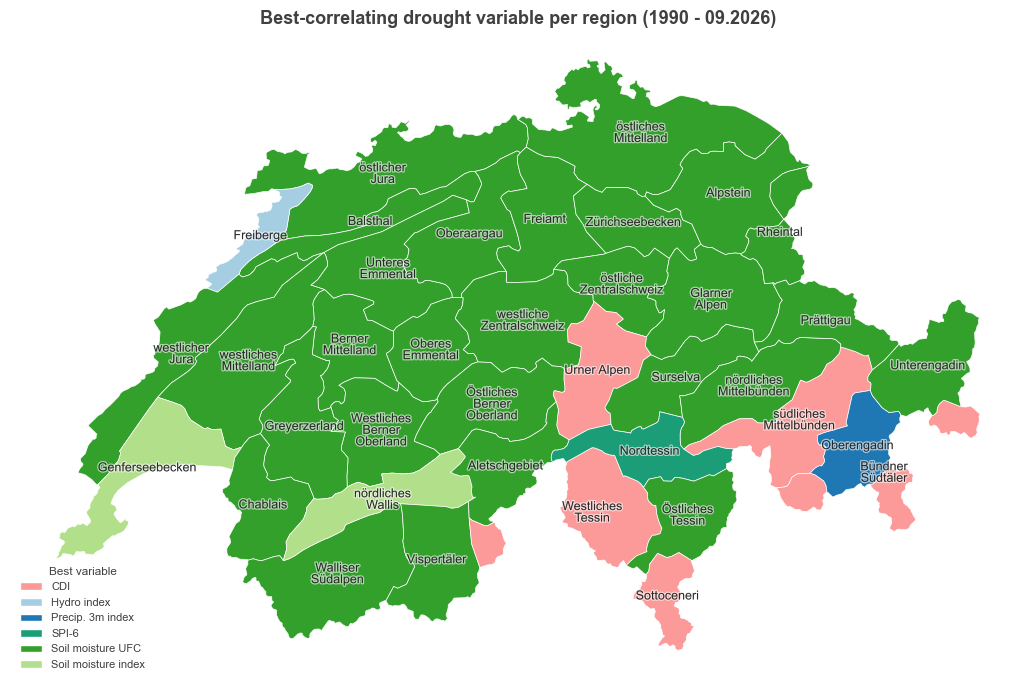

In [31]:
# ============================================================================
# 4.7.2 (map) — PARAMETERS
# ============================================================================
FIG472_METRIC = "pearson_r"
FIG472_TITLE = "Best-correlating drought variable per region (1990 - 09.2026)"
# Fixed colours for the usual winners; anything else gets a colour-blind-safe colour
# from ColorBrewer Dark2 + Set2 (never one already used here).
FIG472_FIXED_VAR_COLORS = {
    "CDI": "#fb9a99", "Hydro index": "#a6cee3", "Precip. 3m index": "#1f78b4",
    "Soil moisture UFC": "#33a02c", "Soil moisture index": "#b2df8a",
}

# ============================================================================
# 4.7.2 (map) — PLOT
# ============================================================================
if not FIG47_READY:
    print("Skipping: run the 4.7 processing cell successfully first.")
else:
    import textwrap
    import matplotlib.patheffects as pe
    from matplotlib.patches import Patch

    set_style(whitegrid=True)
    fallback = [c for c in ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#e6ab02", "#a6761d",
                            "#666666", "#66c2a5", "#fc8d62", "#8da0cb", "#e78ac3", "#a6d854", "#ffd92f",
                            "#e5c494", "#b3b3b3"] if c not in FIG472_FIXED_VAR_COLORS.values()]

    mean_r = region_corrs.groupby(["region_nr", "var_label"])[FIG472_METRIC].mean().reset_index()
    best = (mean_r.sort_values(FIG472_METRIC, ascending=False).drop_duplicates("region_nr")
            .rename(columns={FIG472_METRIC: "best_r"}))
    gdf = regions_gdf.copy()
    gdf["region_nr"] = gdf["Name"].map(REGION_MAP)
    gdf = gdf.merge(best[["region_nr", "var_label", "best_r"]], on="region_nr", how="left")

    winning = sorted(gdf["var_label"].dropna().unique())
    var_color, k = {}, 0
    for v in winning:
        if v in FIG472_FIXED_VAR_COLORS:
            var_color[v] = FIG472_FIXED_VAR_COLORS[v]
        else:
            var_color[v] = fallback[k % len(fallback)]
            k += 1
    gdf["color"] = gdf["var_label"].map(var_color).fillna("#e6e6e6")

    fig, ax = plt.subplots(figsize=(12, 7))
    plot_gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty]
    plot_gdf.plot(color=list(plot_gdf["color"]), edgecolor="white", linewidth=0.5, ax=ax)
    ax.legend(handles=[Patch(facecolor=var_color[v], edgecolor="white", label=v) for v in winning],
              title="Best variable", loc="lower left", fontsize=8, title_fontsize=8.5, framealpha=0.9)
    for _, row in plot_gdf.iterrows():
        c = row.geometry.centroid
        ax.text(c.x, c.y, textwrap.fill(row["Name"], width=11, break_long_words=False, break_on_hyphens=False),
                ha="center", va="center", fontsize=9, color="#111111", alpha=0.85, linespacing=0.95,
                path_effects=[pe.withStroke(linewidth=1.8, foreground="white", alpha=0.6)])
    ax.set_title(FIG472_TITLE, fontsize=13, fontweight="bold", loc="center", pad=4)
    ax.set_axis_off()
    plt.tight_layout()
    fig.savefig(os.path.join(FIGURES_DIR, "4.7.2_best_variable_map.png"), dpi=200, bbox_inches="tight")
    plt.show()

## 4.7.2 — Mean Pearson r per region, for chosen indicators (thesis Figure 21)

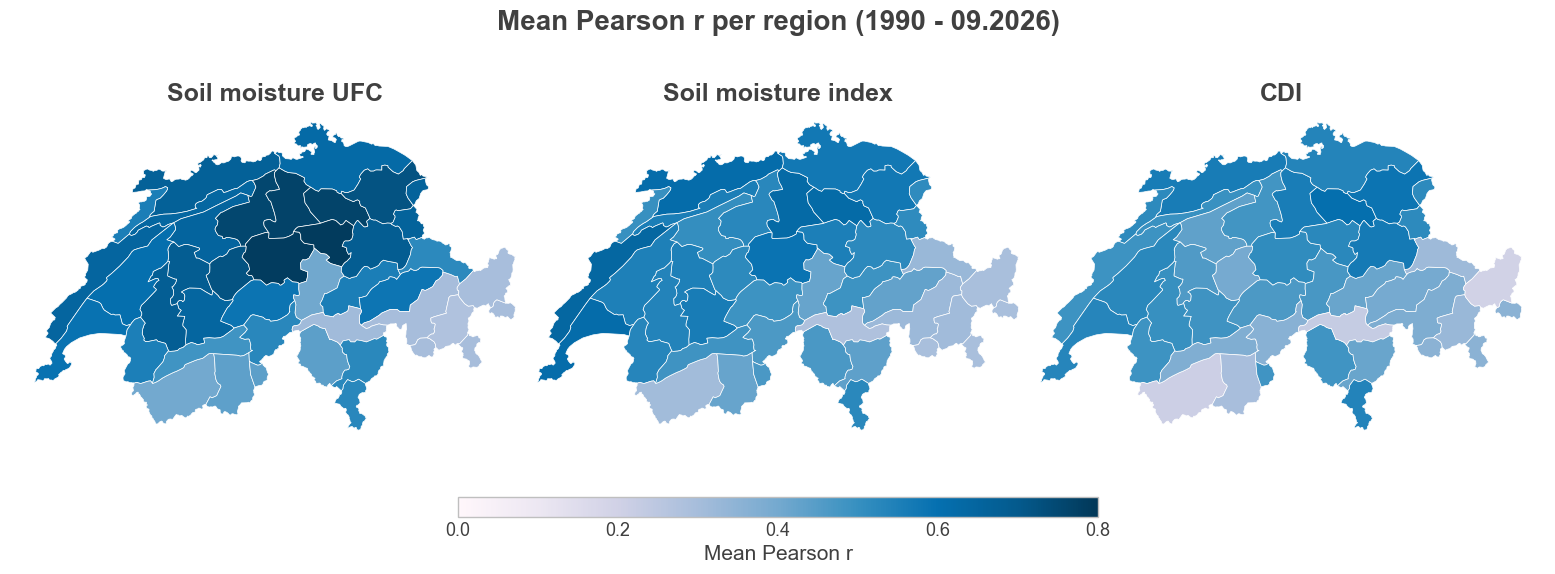

In [32]:
# ============================================================================
# 4.7.2 (small maps) — PARAMETERS
# ============================================================================
FIG472S_VARS = ["soil_moisture_ufc", "soil_moisture_index", "cdi"]
FIG472S_VMIN, FIG472S_VMAX = 0.0, 0.8

# ============================================================================
# 4.7.2 (small maps) — PLOT
# ============================================================================
if not FIG47_READY:
    print("Skipping: run the 4.7 processing cell successfully first.")
else:
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import Normalize

    set_style(whitegrid=True)
    cmap, norm = plt.cm.PuBu, Normalize(vmin=FIG472S_VMIN, vmax=FIG472S_VMAX)
    n = len(FIG472S_VARS)
    fig, axes = plt.subplots(1, n, figsize=(16 / 3 * n, 6.5))
    axes = np.atleast_1d(axes)
    for ax, var in zip(axes, FIG472S_VARS):
        mr = (region_corrs[region_corrs["drought_var"] == var].groupby("region_nr")["pearson_r"].mean()
              .rename("mean_r").reset_index())
        gdf = regions_gdf.copy()
        gdf["region_nr"] = gdf["Name"].map(REGION_MAP)
        gdf.merge(mr, on="region_nr", how="left").plot(column="mean_r", cmap=cmap, norm=norm, legend=False,
                                                       edgecolor="white", linewidth=0.5, ax=ax,
                                                       missing_kwds={"color": "#eeeeee"})
        ax.set_title(DROUGHT_VAR_LABELS.get(var, var), fontsize=18, fontweight="bold", loc="center", pad=4)
        ax.set_axis_off()

    fig.suptitle("Mean Pearson r per region (1990 - 09.2026)", fontsize=20, fontweight="bold", x=0.5, y=0.85, ha="center")
    fig.subplots_adjust(bottom=0, top=0.88, wspace=-0.05, left=0.02, right=0.98)
    sm = ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=fig.add_axes([0.30, 0.07, 0.40, 0.03]), orientation="horizontal")
    cbar.set_ticks(np.linspace(FIG472S_VMIN, FIG472S_VMAX, 5))
    cbar.set_label("Mean Pearson r", fontsize=15)
    cbar.ax.tick_params(labelsize=13)
    fig.savefig(os.path.join(FIGURES_DIR, "4.7.2_spatial_correlation_map.png"), dpi=200, bbox_inches="tight")
    plt.show()

## 4.7.3 — Mean region-level correlation by drought variable and language (thesis Figure 22)

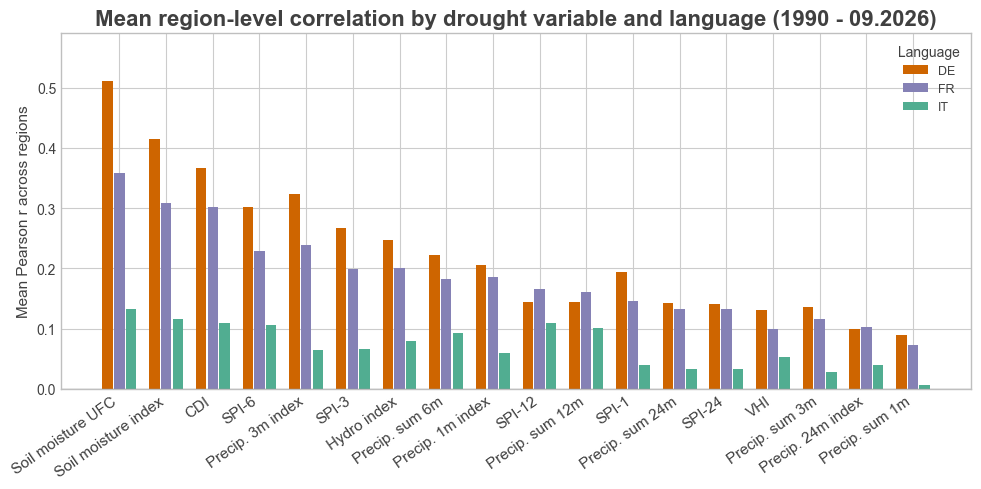

Mean region-level correlation by drought variable and language (1990 - 09.2026):

language                DE     FR     IT
var_label                               
Soil moisture UFC    0.511  0.359  0.132
Soil moisture index  0.415  0.308  0.116
CDI                  0.367  0.302  0.110
SPI-6                0.302  0.229  0.105
Precip. 3m index     0.324  0.239  0.064
SPI-3                0.268  0.199  0.066
Hydro index          0.247  0.201  0.079
Precip. sum 6m       0.223  0.183  0.093
Precip. 1m index     0.205  0.186  0.059
SPI-12               0.144  0.165  0.109
Precip. sum 12m      0.143  0.161  0.100
SPI-1                0.194  0.146  0.039
Precip. sum 24m      0.143  0.132  0.032
SPI-24               0.141  0.132  0.033
VHI                  0.131  0.099  0.052
Precip. sum 3m       0.135  0.116  0.028
Precip. 24m index    0.099  0.102  0.040
Precip. sum 1m       0.089  0.072  0.006


In [33]:
# ============================================================================
# 4.7.3 — PARAMETERS
# ============================================================================
FIG473_LANGUAGES = LANGUAGES
FIG473_MAX_VARS = None     # None = all 18 indicators, or a number for the top N

# ============================================================================
# 4.7.3 — PLOT
# ============================================================================
if not FIG47_READY or combined.empty:
    print("Skipping: run the 4.7 processing cell successfully first.")
else:
    set_style(whitegrid=True)
    langs473 = [l for l in FIG473_LANGUAGES if l in set(combined["language"])]
    pivot_plot = combined.pivot_table(index="var_label", columns="language", values="mean_r")
    pivot_plot = pivot_plot.loc[pivot_plot[langs473].mean(axis=1).sort_values(ascending=False).index]
    if FIG473_MAX_VARS:
        pivot_plot = pivot_plot.head(FIG473_MAX_VARS)

    fig, ax = plt.subplots(figsize=(10, 5))
    x = np.arange(len(pivot_plot))
    width = 0.25
    offsets = np.linspace(-(len(langs473) - 1) * width / 2, (len(langs473) - 1) * width / 2, len(langs473))
    for offset, lang in zip(offsets, langs473):
        ax.bar(x + offset, pivot_plot[lang], width=width * 0.9, label=lang, color=LANGUAGE_COLORS.get(lang, "steelblue"))
    ax.set_xticks(x)
    ax.set_xticklabels(pivot_plot.index, rotation=35, ha="right", fontsize=11)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylabel("Mean Pearson r across regions", fontsize=11)
    ax.set_title("Mean region-level correlation by drought variable and language (1990 - 09.2026)", fontsize=16,
                 fontweight="bold", loc="center")
    ax.legend(title="Language", fontsize=9)
    ax.set_ylim(min(0, np.nanmin(pivot_plot[langs473].values) * 1.1), ax.get_ylim()[1] * 1.1)
    plt.tight_layout()
    fig.savefig(os.path.join(FIGURES_DIR, "4.7.3_mean_correlation_by_language.png"), dpi=200, bbox_inches="tight")
    plt.show()

    print("Mean region-level correlation by drought variable and language (1990 - 09.2026):\n")
    print(pivot_plot[langs473].round(3).to_string())

## 4.7.4 — National drought indicators vs. media coverage (thesis Figure 23)
One panel per top-correlating indicator (national average, oriented so higher = drier),
overlaid with normalised national media coverage. Grey bands mark major drought years.

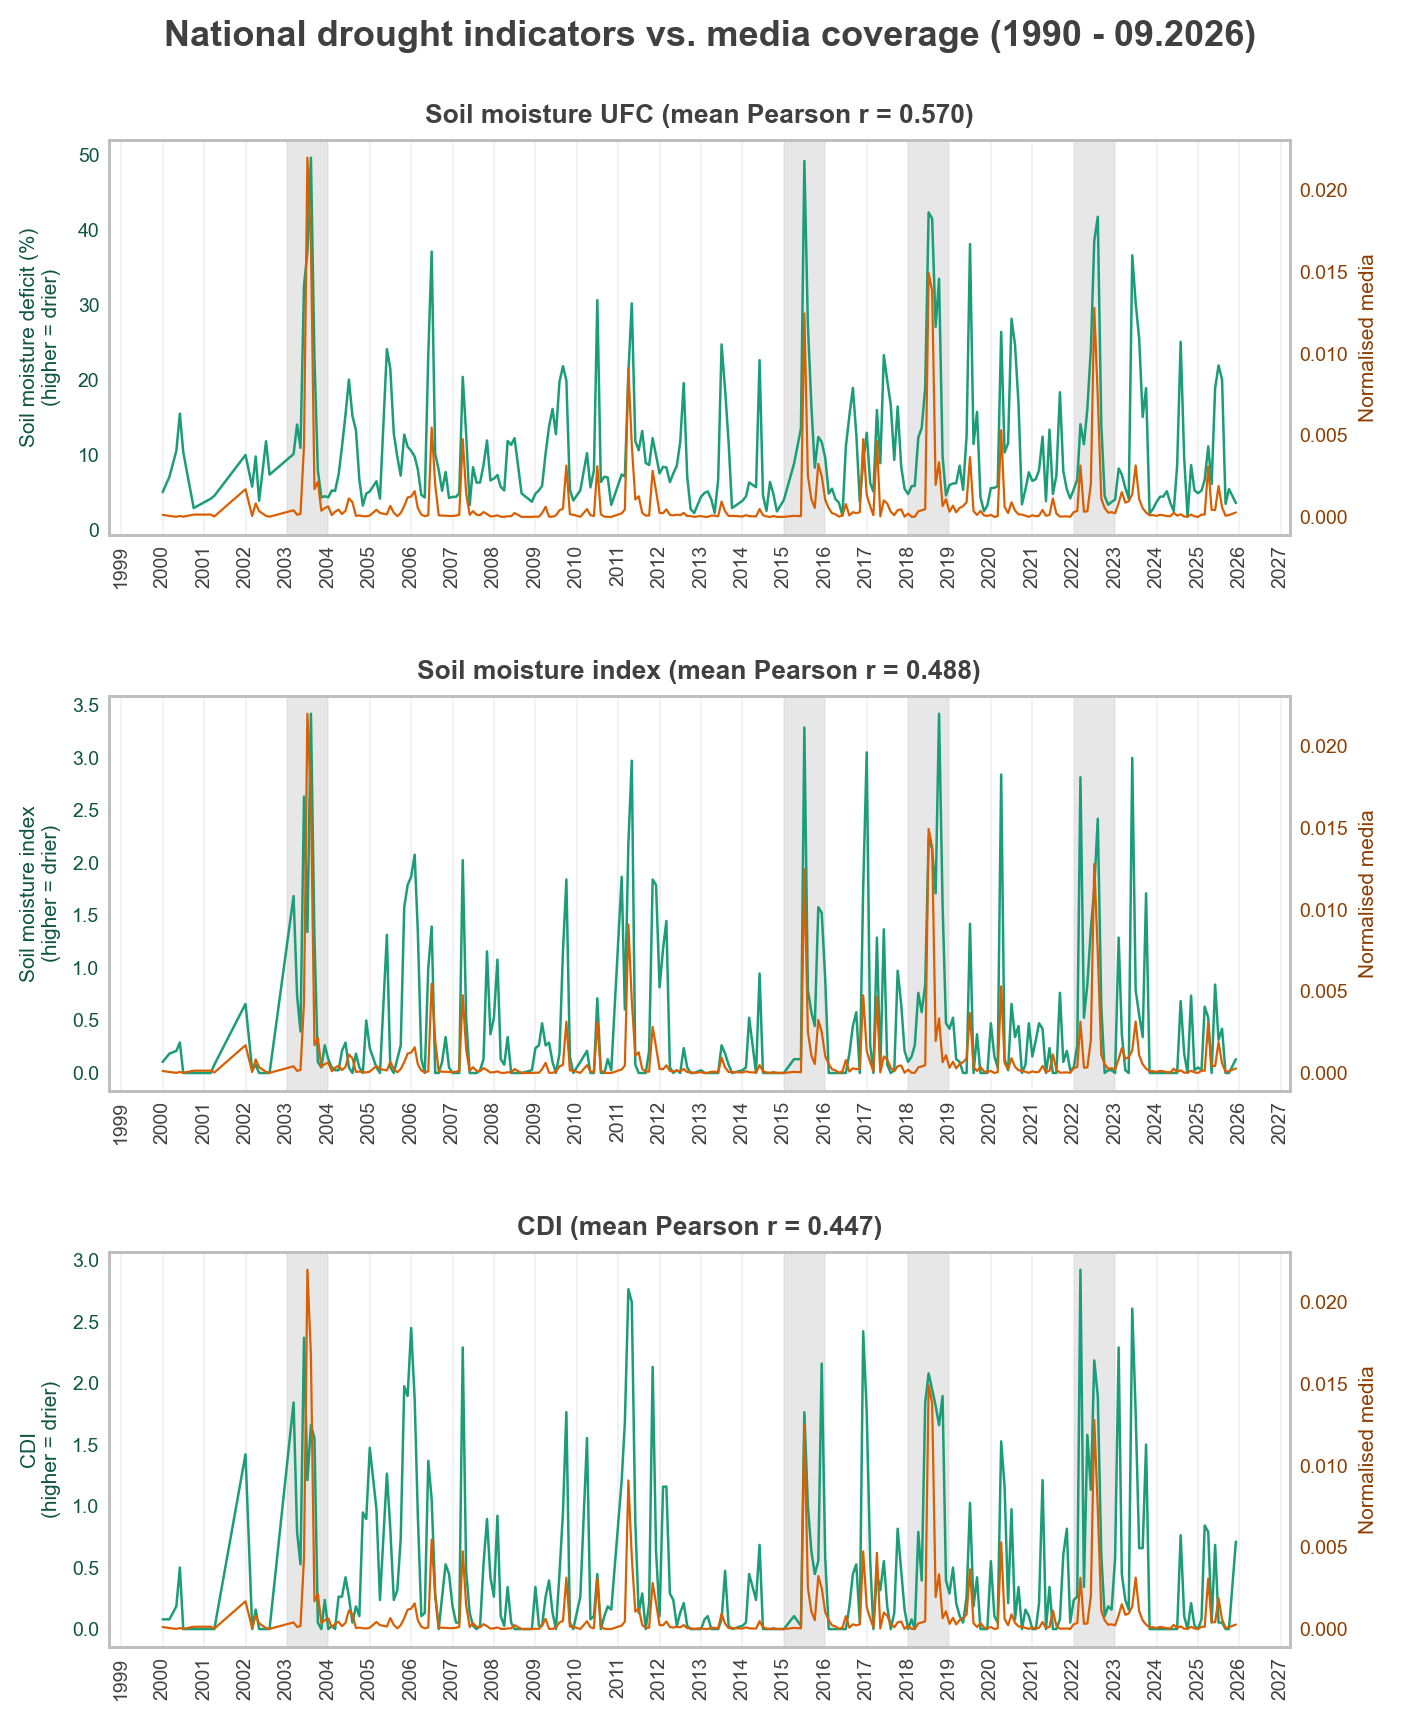

In [34]:
# ============================================================================
# 4.7.4 — PARAMETERS
# ============================================================================
FIG474_TOP_N = 3
FIG474_MAJOR_DROUGHT_YEARS = (2003, 2015, 2018, 2022)

# ============================================================================
# 4.7.4 — PLOT
# ============================================================================
if not FIG47_READY:
    print("Skipping: run the 4.7 processing cell successfully first.")
else:
    import matplotlib.dates as mdates

    set_style(whitegrid=True)
    plt.rcParams.update({"axes.titlecolor": "#404040"})

    def darken(hex_color, factor):
        r, g, b = (int(hex_color.lstrip("#")[i:i + 2], 16) for i in (0, 2, 4))
        return "#{:02x}{:02x}{:02x}".format(*(int(c * (1 - factor)) for c in (r, g, b)))

    COLOR_DROUGHT, COLOR_MEDIA = "#1b9e77", "#d95f02"          # ColorBrewer Dark2
    TEXT_DROUGHT, TEXT_MEDIA = darken(COLOR_DROUGHT, 0.45), darken(COLOR_MEDIA, 0.35)
    CDI_LIKE = {"cdi", "precip_1m_index", "precip_3m_index", "precip_24m_index", "hydro_index", "soil_moisture_index"}

    def display_series(series, var):
        if var == "soil_moisture_ufc":
            return 100 - series, "Soil moisture deficit (%)\n(higher = drier)"
        if var in CDI_LIKE:
            return series - 1, f"{DROUGHT_VAR_LABELS.get(var, var)}\n(higher = drier)"
        return -series, f"{DROUGHT_VAR_LABELS.get(var, var)}\n(higher = drier)"

    top_vars = summary.head(FIG474_TOP_N)["drought_var"].tolist()
    drought_nat = (drought_monthly.groupby(["year", "month", "month_start"], as_index=False)[top_vars].mean()
                   .sort_values("month_start"))
    media_nat = (media_all_languages(FIG47_LANGS_USED).groupby(["year", "month", "month_start"], as_index=False)["Media"].sum()
                 .merge(baseline_for(FIG47_LANGS_USED)[["year", "month", "month_start", "baseline_total"]],
                        on=["year", "month", "month_start"], how="left"))
    media_nat["Media_norm"] = safe_divide(media_nat["Media"], media_nat["baseline_total"])
    merged = drought_nat.merge(media_nat[["year", "month", "month_start", "Media_norm"]],
                               on=["year", "month", "month_start"], how="inner")
    merged = merged[merged["year"].between(FIG47_Y0, FIG47_Y1)].copy()
    merged["Media_wins"] = winsorize_series(merged["Media_norm"])

    fig, axes = plt.subplots(len(top_vars), 1, figsize=(7.2, 3.0 * len(top_vars)), sharex=True, dpi=200)
    axes = np.atleast_1d(axes)
    for ax, var in zip(axes, top_vars):
        series, y_label = display_series(merged[var], var)
        row = summary[summary["drought_var"] == var].iloc[0]
        ax.plot(merged["month_start"], series, color=COLOR_DROUGHT, linewidth=0.9)
        ax.set_ylabel(y_label, fontsize=7.5, color=TEXT_DROUGHT)
        ax.tick_params(axis="y", labelcolor=TEXT_DROUGHT, labelsize=7)
        ax2 = ax.twinx()
        ax2.plot(merged["month_start"], merged["Media_wins"], color=COLOR_MEDIA, linewidth=0.8)
        ax2.set_ylabel("Normalised media\n", fontsize=7.5, color=TEXT_MEDIA)
        ax2.tick_params(axis="y", labelcolor=TEXT_MEDIA, labelsize=7)
        for yr in FIG474_MAJOR_DROUGHT_YEARS:
            ax.axvspan(pd.Timestamp(f"{yr}-01-01"), pd.Timestamp(f"{yr + 1}-01-01"),
                       color="#bbbbbb", alpha=0.35, zorder=0, linewidth=0)
        ax.set_title(f"{DROUGHT_VAR_LABELS.get(var, var)} (mean Pearson r = {row['mean_pearson_r']:.3f})",
                     fontsize=9.5, fontweight="bold", loc="center", pad=6)
        ax.grid(axis="x", alpha=0.3, linewidth=0.6)
        ax.grid(axis="y", visible=False)
        ax2.grid(False)
        ax.xaxis.set_major_locator(mdates.YearLocator(1))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
        ax.tick_params(axis="x", labelbottom=True, labelsize=7, rotation=90)
        ax.set_xlabel("")

    fig.align_ylabels(axes)
    fig.suptitle("National drought indicators vs. media coverage (1990 - 09.2026)", fontsize=13, fontweight="bold",
                 x=0.5, y=0.95, ha="center")
    plt.tight_layout(h_pad=2.6, rect=(0, 0, 1, 0.955))
    fig.savefig(os.path.join(FIGURES_DIR, "4.7.4_national_timeseries.png"), dpi=200, bbox_inches="tight")
    plt.show()